# Credit Risk Assessment in MSME Lending: How Banks Can Improve Without Raising NPAs

Dataset Source:-https://www.kaggle.com/datasets/nikhil1e9/loan-default

# **Import Required Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV

**Load Dataset**

In [2]:
df = pd.read_csv('Loan_default.csv')
print(df.shape)
df.head()

(255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


**Dataset Information**

In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (255347, 18)

Column Names:
['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education    

**Statistical Summary**

In [4]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


**Missing Values Check**

In [5]:
missing_values = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing_values)
print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

Total Missing Values: 0


**Duplicate Records Check**

In [6]:
duplicate_rows = df.duplicated().sum()
print("Number of Duplicate Rows:", duplicate_rows)

Number of Duplicate Rows: 0


**Unique LoanID Check**

In [7]:
unique_loan_ids = df['LoanID'].nunique()
duplicate_loan_ids = df['LoanID'].duplicated().sum()
print("Total Records:", len(df))
print("Unique LoanIDs:", unique_loan_ids)
print("Duplicate LoanIDs:", duplicate_loan_ids)

Total Records: 255347
Unique LoanIDs: 255347
Duplicate LoanIDs: 0


**Identify Numerical, Categorical and Target Variables**

In [8]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numerical_features.remove('Default')
categorical_features = df.select_dtypes(include=['object']).columns.tolist()
categorical_features.remove('LoanID')
target_variable = 'Default'
print("Numerical Features:")
print(numerical_features)
print("\nCategorical Features:")
print(categorical_features)
print("\nTarget Variable:")
print(target_variable)

Numerical Features:
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

Categorical Features:
['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']

Target Variable:
Default


**Check Unique Values in Categorical Variables**

In [9]:
for column in categorical_features:
    print(f"\n{column}")
    print("Number of Unique Values:", df[column].nunique())
    print("Categories:", df[column].unique())


Education
Number of Unique Values: 4
Categories: ["Bachelor's" "Master's" 'High School' 'PhD']

EmploymentType
Number of Unique Values: 4
Categories: ['Full-time' 'Unemployed' 'Self-employed' 'Part-time']

MaritalStatus
Number of Unique Values: 3
Categories: ['Divorced' 'Married' 'Single']

HasMortgage
Number of Unique Values: 2
Categories: ['Yes' 'No']

HasDependents
Number of Unique Values: 2
Categories: ['Yes' 'No']

LoanPurpose
Number of Unique Values: 5
Categories: ['Other' 'Auto' 'Business' 'Home' 'Education']

HasCoSigner
Number of Unique Values: 2
Categories: ['Yes' 'No']


**Target Variable Distribution**

In [10]:
default_counts = df['Default'].value_counts().sort_index()
print("Default Counts:")
print(default_counts)
default_percentages = df['Default'].value_counts(normalize=True).sort_index() * 100
print("\nDefault Percentages:")
print(default_percentages.round(2))

Default Counts:
Default
0    225694
1     29653
Name: count, dtype: int64

Default Percentages:
Default
0    88.39
1    11.61
Name: proportion, dtype: float64


**Target Distribution Visualisation**

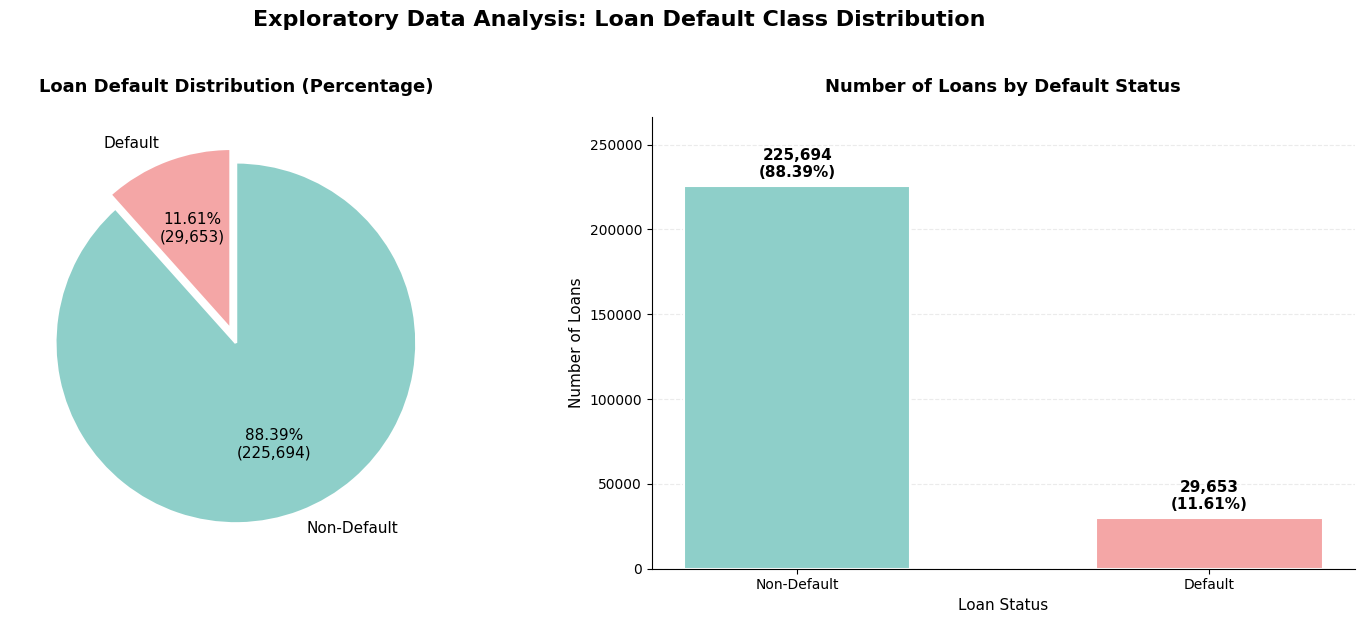

LOAN DEFAULT DISTRIBUTION - KEY INSIGHTS
Total Loan Records       : 255,347
Non-Default Loans        : 225,694 (88.39%)
Default Loans            : 29,653 (11.61%)

Default-to-Non-Default Ratio: 1:7.61
Class Percentage Difference: 76.77%

EDA Interpretation:
Approximately 88.39% of borrowers did not default, whereas 11.61% experienced loan default.
The target variable exhibits class imbalance, with non-default cases substantially exceeding default cases.
Therefore, model evaluation should consider precision, recall, F1-score, ROC-AUC and Precision-Recall AUC rather than relying on accuracy alone.


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

default_counts = df['Default'].value_counts().sort_index()
default_percentages = (default_counts / len(df)) * 100

labels = ['Non-Default', 'Default']
colors = ['#8ECFC9', '#F4A6A6']

fig, axes = plt.subplots(1, 2, figsize=(15, 6))


def autopct_format(pct):
    count = int(round(pct * len(df) / 100))
    return f'{pct:.2f}%\n({count:,})'

axes[0].pie(
    default_counts,
    labels=labels,
    colors=colors,
    autopct=autopct_format,
    startangle=90,
    counterclock=False,
    explode=(0, 0.08),
    shadow=False,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 11}
)

axes[0].set_title(
    'Loan Default Distribution (Percentage)',
    fontsize=13,
    fontweight='bold',
    pad=18
)

bars = axes[1].bar(
    labels,
    default_counts.values,
    color=colors,
    width=0.55,
    edgecolor='white',
    linewidth=1.5
)

for bar, count, percentage in zip(
    bars,
    default_counts.values,
    default_percentages.values
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3500,
        f'{count:,}\n({percentage:.2f}%)',
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

axes[1].set_title(
    'Number of Loans by Default Status',
    fontsize=13,
    fontweight='bold',
    pad=18
)

axes[1].set_xlabel('Loan Status', fontsize=11)
axes[1].set_ylabel('Number of Loans', fontsize=11)
axes[1].set_ylim(0, max(default_counts.values) * 1.18)

axes[1].grid(axis='y', linestyle='--', alpha=0.25)
axes[1].set_axisbelow(True)

sns.despine(ax=axes[1])

fig.suptitle(
    'Exploratory Data Analysis: Loan Default Class Distribution',
    fontsize=16,
    fontweight='bold',
    y=1.03
)

plt.tight_layout()
plt.show()

non_default_count = default_counts[0]
default_count = default_counts[1]

print("=" * 65)
print("LOAN DEFAULT DISTRIBUTION - KEY INSIGHTS")
print("=" * 65)

print(f"Total Loan Records       : {len(df):,}")
print(f"Non-Default Loans        : {non_default_count:,} ({default_percentages[0]:.2f}%)")
print(f"Default Loans            : {default_count:,} ({default_percentages[1]:.2f}%)")

print(f"\nDefault-to-Non-Default Ratio: 1:{non_default_count/default_count:.2f}")

print(f"Class Percentage Difference: {default_percentages[0]-default_percentages[1]:.2f}%")

print("\nEDA Interpretation:")
print(
    f"Approximately {default_percentages[0]:.2f}% of borrowers "
    f"did not default, whereas {default_percentages[1]:.2f}% "
    f"experienced loan default."
)

print(
    "The target variable exhibits class imbalance, "
    "with non-default cases substantially exceeding default cases."
)

print(
    "Therefore, model evaluation should consider precision, recall, "
    "F1-score, ROC-AUC and Precision-Recall AUC rather than relying "
    "on accuracy alone."
)

print("=" * 65)

**Numerical Variables - Range and Unique Value Check**

In [12]:
numerical_validation = pd.DataFrame({
    'Data Type': df[numerical_features].dtypes,
    'Unique Values': df[numerical_features].nunique(),
    'Minimum': df[numerical_features].min(),
    'Maximum': df[numerical_features].max()
})
display(numerical_validation)

,Data Type,Unique Values,Minimum,Maximum
Age,int64,52,18.0,69.0
Income,int64,114620,15000.0,149999.0
LoanAmount,int64,158729,5000.0,249999.0
CreditScore,int64,550,300.0,849.0
MonthsEmployed,int64,120,0.0,119.0
NumCreditLines,int64,4,1.0,4.0
InterestRate,float64,2301,2.0,25.0
LoanTerm,int64,5,12.0,60.0
DTIRatio,float64,81,0.1,0.9


**Categorical Variables - Frequency Check**

In [13]:
for column in categorical_features:
    print(f"\n{'=' * 50}")
    print(f"{column}")
    print(f"{'=' * 50}")
    print(df[column].value_counts())


Education
Education
Bachelor's     64366
High School    63903
Master's       63541
PhD            63537
Name: count, dtype: int64

EmploymentType
EmploymentType
Part-time        64161
Unemployed       63824
Self-employed    63706
Full-time        63656
Name: count, dtype: int64

MaritalStatus
MaritalStatus
Married     85302
Divorced    85033
Single      85012
Name: count, dtype: int64

HasMortgage
HasMortgage
Yes    127677
No     127670
Name: count, dtype: int64

HasDependents
HasDependents
Yes    127742
No     127605
Name: count, dtype: int64

LoanPurpose
LoanPurpose
Business     51298
Home         51286
Education    51005
Other        50914
Auto         50844
Name: count, dtype: int64

HasCoSigner
HasCoSigner
Yes    127701
No     127646
Name: count, dtype: int64


# **Exploratory Data Analysis**

**Distribution of Numerical Variables**

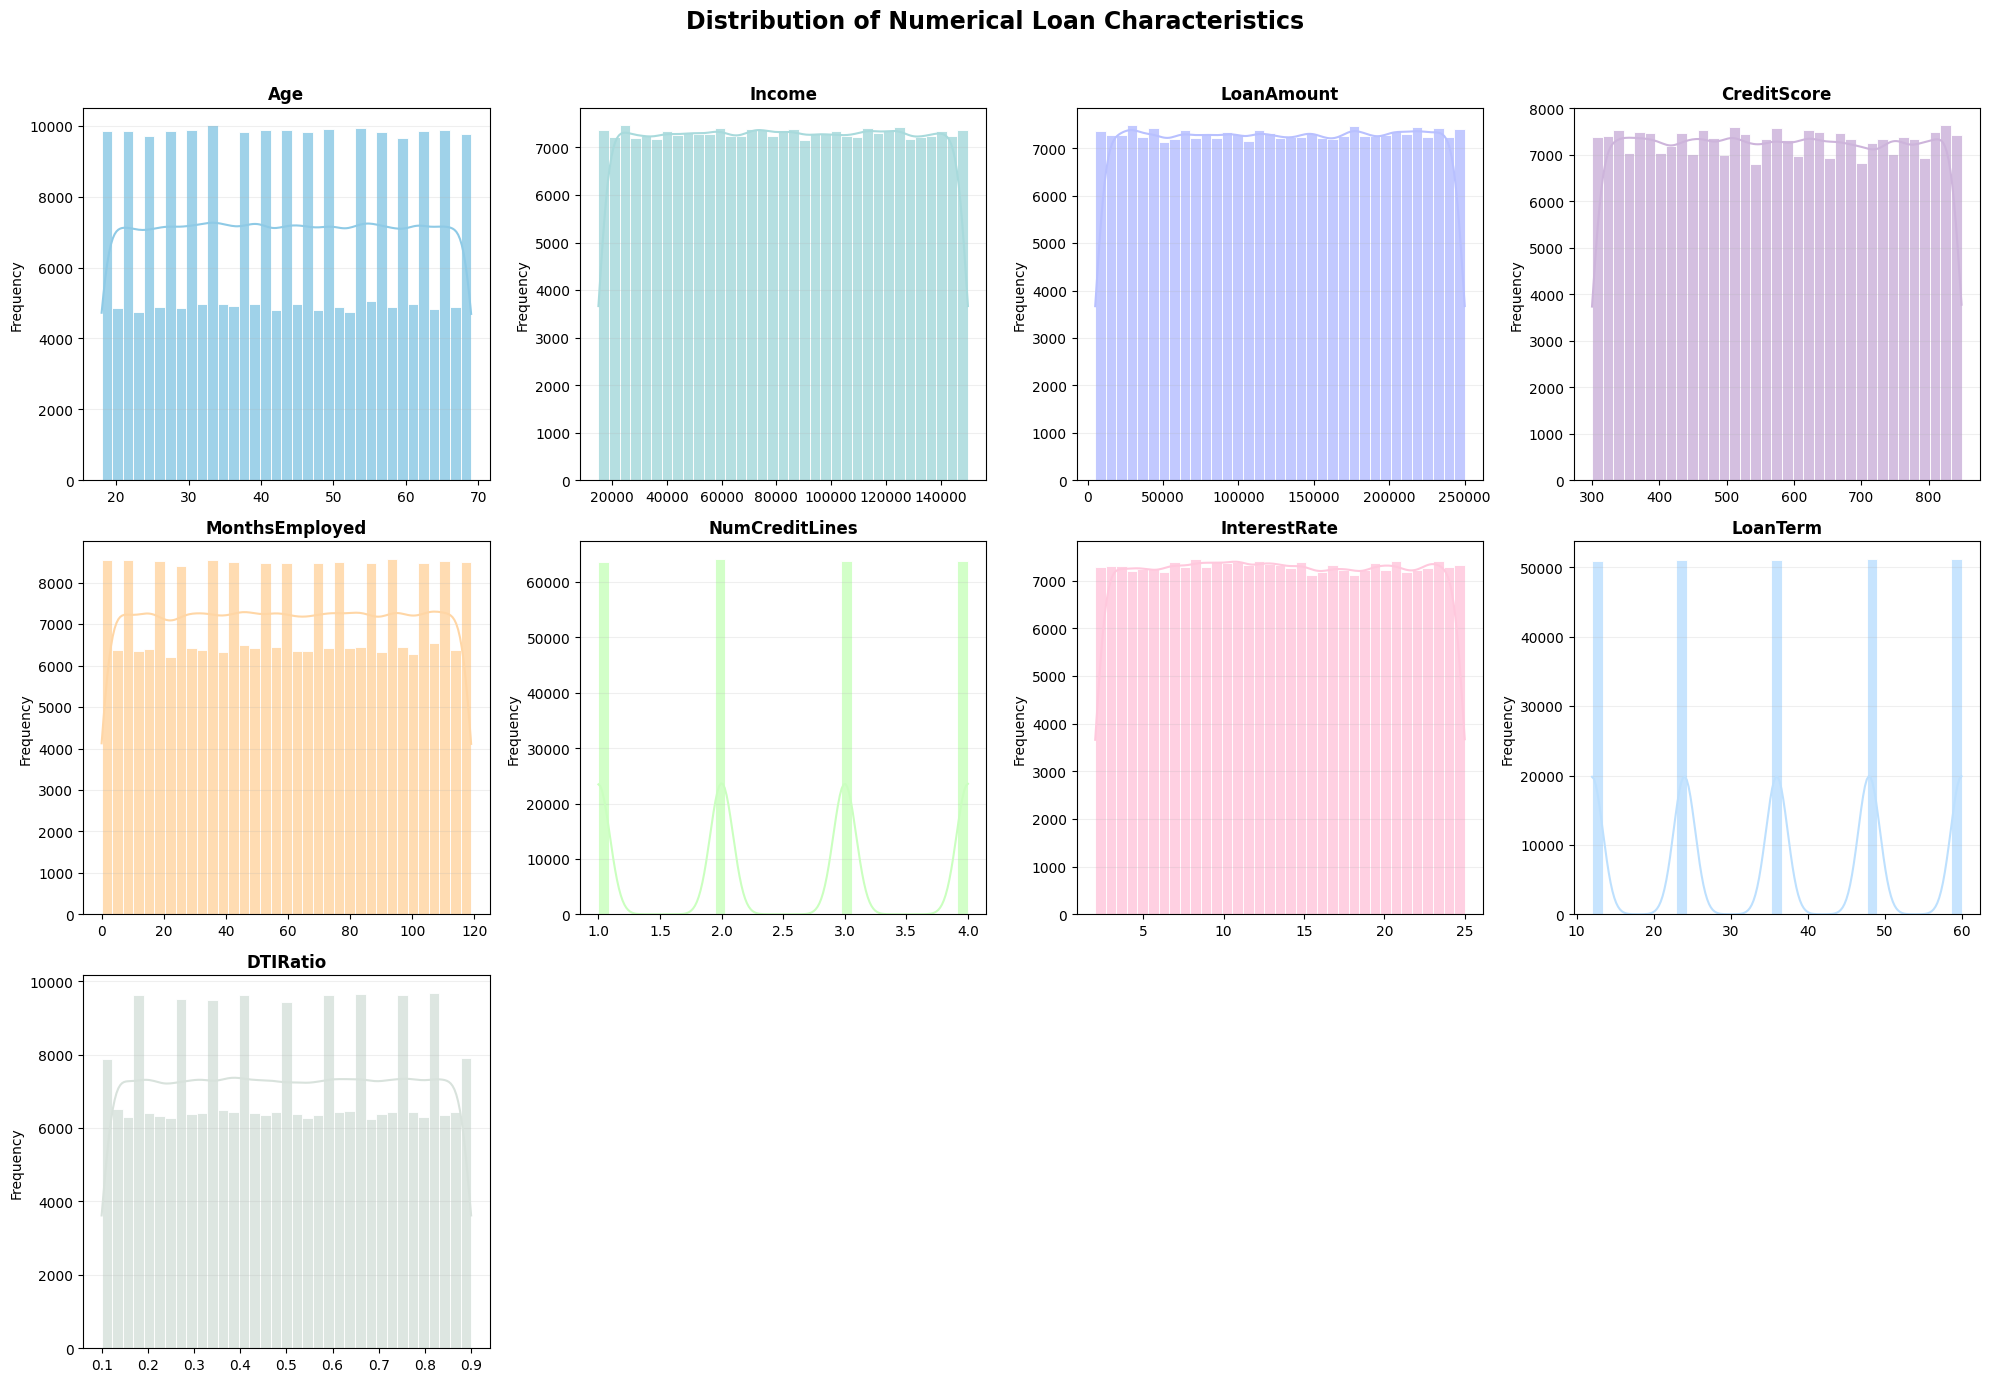

,Mean,Median,Standard Deviation,Skewness,Minimum,Maximum
Age,43.50,43.00,14.99,0.0,18.0,69.0
Income,82499.30,82466.00,38963.01,-0.0,15000.0,149999.0
LoanAmount,127578.87,127556.00,70840.71,-0.0,5000.0,249999.0
CreditScore,574.26,574.00,158.90,0.0,300.0,849.0
MonthsEmployed,59.54,60.00,34.64,-0.0,0.0,119.0
NumCreditLines,2.50,2.00,1.12,-0.0,1.0,4.0
InterestRate,13.49,13.46,6.64,0.0,2.0,25.0
LoanTerm,36.03,36.00,16.97,-0.0,12.0,60.0
DTIRatio,0.50,0.50,0.23,-0.0,0.1,0.9



KEY DISTRIBUTION INSIGHTS

Age
  Mean             : 43.50
  Median           : 43.00
  Skewness         : 0.001
  Distribution    : Approximately symmetric

Income
  Mean             : 82,499.30
  Median           : 82,466.00
  Skewness         : -0.000
  Distribution    : Approximately symmetric

LoanAmount
  Mean             : 127,578.87
  Median           : 127,556.00
  Skewness         : -0.002
  Distribution    : Approximately symmetric

CreditScore
  Mean             : 574.26
  Median           : 574.00
  Skewness         : 0.005
  Distribution    : Approximately symmetric

MonthsEmployed
  Mean             : 59.54
  Median           : 60.00
  Skewness         : -0.002
  Distribution    : Approximately symmetric

NumCreditLines
  Mean             : 2.50
  Median           : 2.00
  Skewness         : -0.000
  Distribution    : Approximately symmetric

InterestRate
  Mean             : 13.49
  Median           : 13.46
  Skewness         : 0.005
  Distribution    : Approximately sy

In [14]:
fig, axes = plt.subplots(5, 4, figsize=(20, 22))
axes = axes.flatten()

colors = ['#8ECAE6', '#A8DADC', '#B8C0FF',
          '#CDB4DB', '#FFD6A5', '#CAFFBF',
          '#FFC8DD', '#BDE0FE', '#D8E2DC']

for i, column in enumerate(numerical_features):

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=35,
        color=colors[i % len(colors)],
        edgecolor='white',
        alpha=0.85,
        ax=axes[i]
    )

    axes[i].set_title(column, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequency')
    axes[i].grid(axis='y', alpha=0.2)

for j in range(len(numerical_features), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    'Distribution of Numerical Loan Characteristics',
    fontsize=17,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()



distribution_summary = pd.DataFrame({
    'Mean': df[numerical_features].mean(),
    'Median': df[numerical_features].median(),
    'Standard Deviation': df[numerical_features].std(),
    'Skewness': df[numerical_features].skew(),
    'Minimum': df[numerical_features].min(),
    'Maximum': df[numerical_features].max()
})

distribution_summary = distribution_summary.round(2)

display(distribution_summary)

print("\nKEY DISTRIBUTION INSIGHTS")
print("=" * 65)

for column in numerical_features:

    skew = df[column].skew()
    mean = df[column].mean()
    median = df[column].median()

    if skew > 0.5:
        shape = "Positively skewed (right-tailed)"
    elif skew < -0.5:
        shape = "Negatively skewed (left-tailed)"
    else:
        shape = "Approximately symmetric"

    print(f"\n{column}")
    print(f"  Mean             : {mean:,.2f}")
    print(f"  Median           : {median:,.2f}")
    print(f"  Skewness         : {skew:.3f}")
    print(f"  Distribution    : {shape}")

**Distribution of Numerical Variables by Default Status**

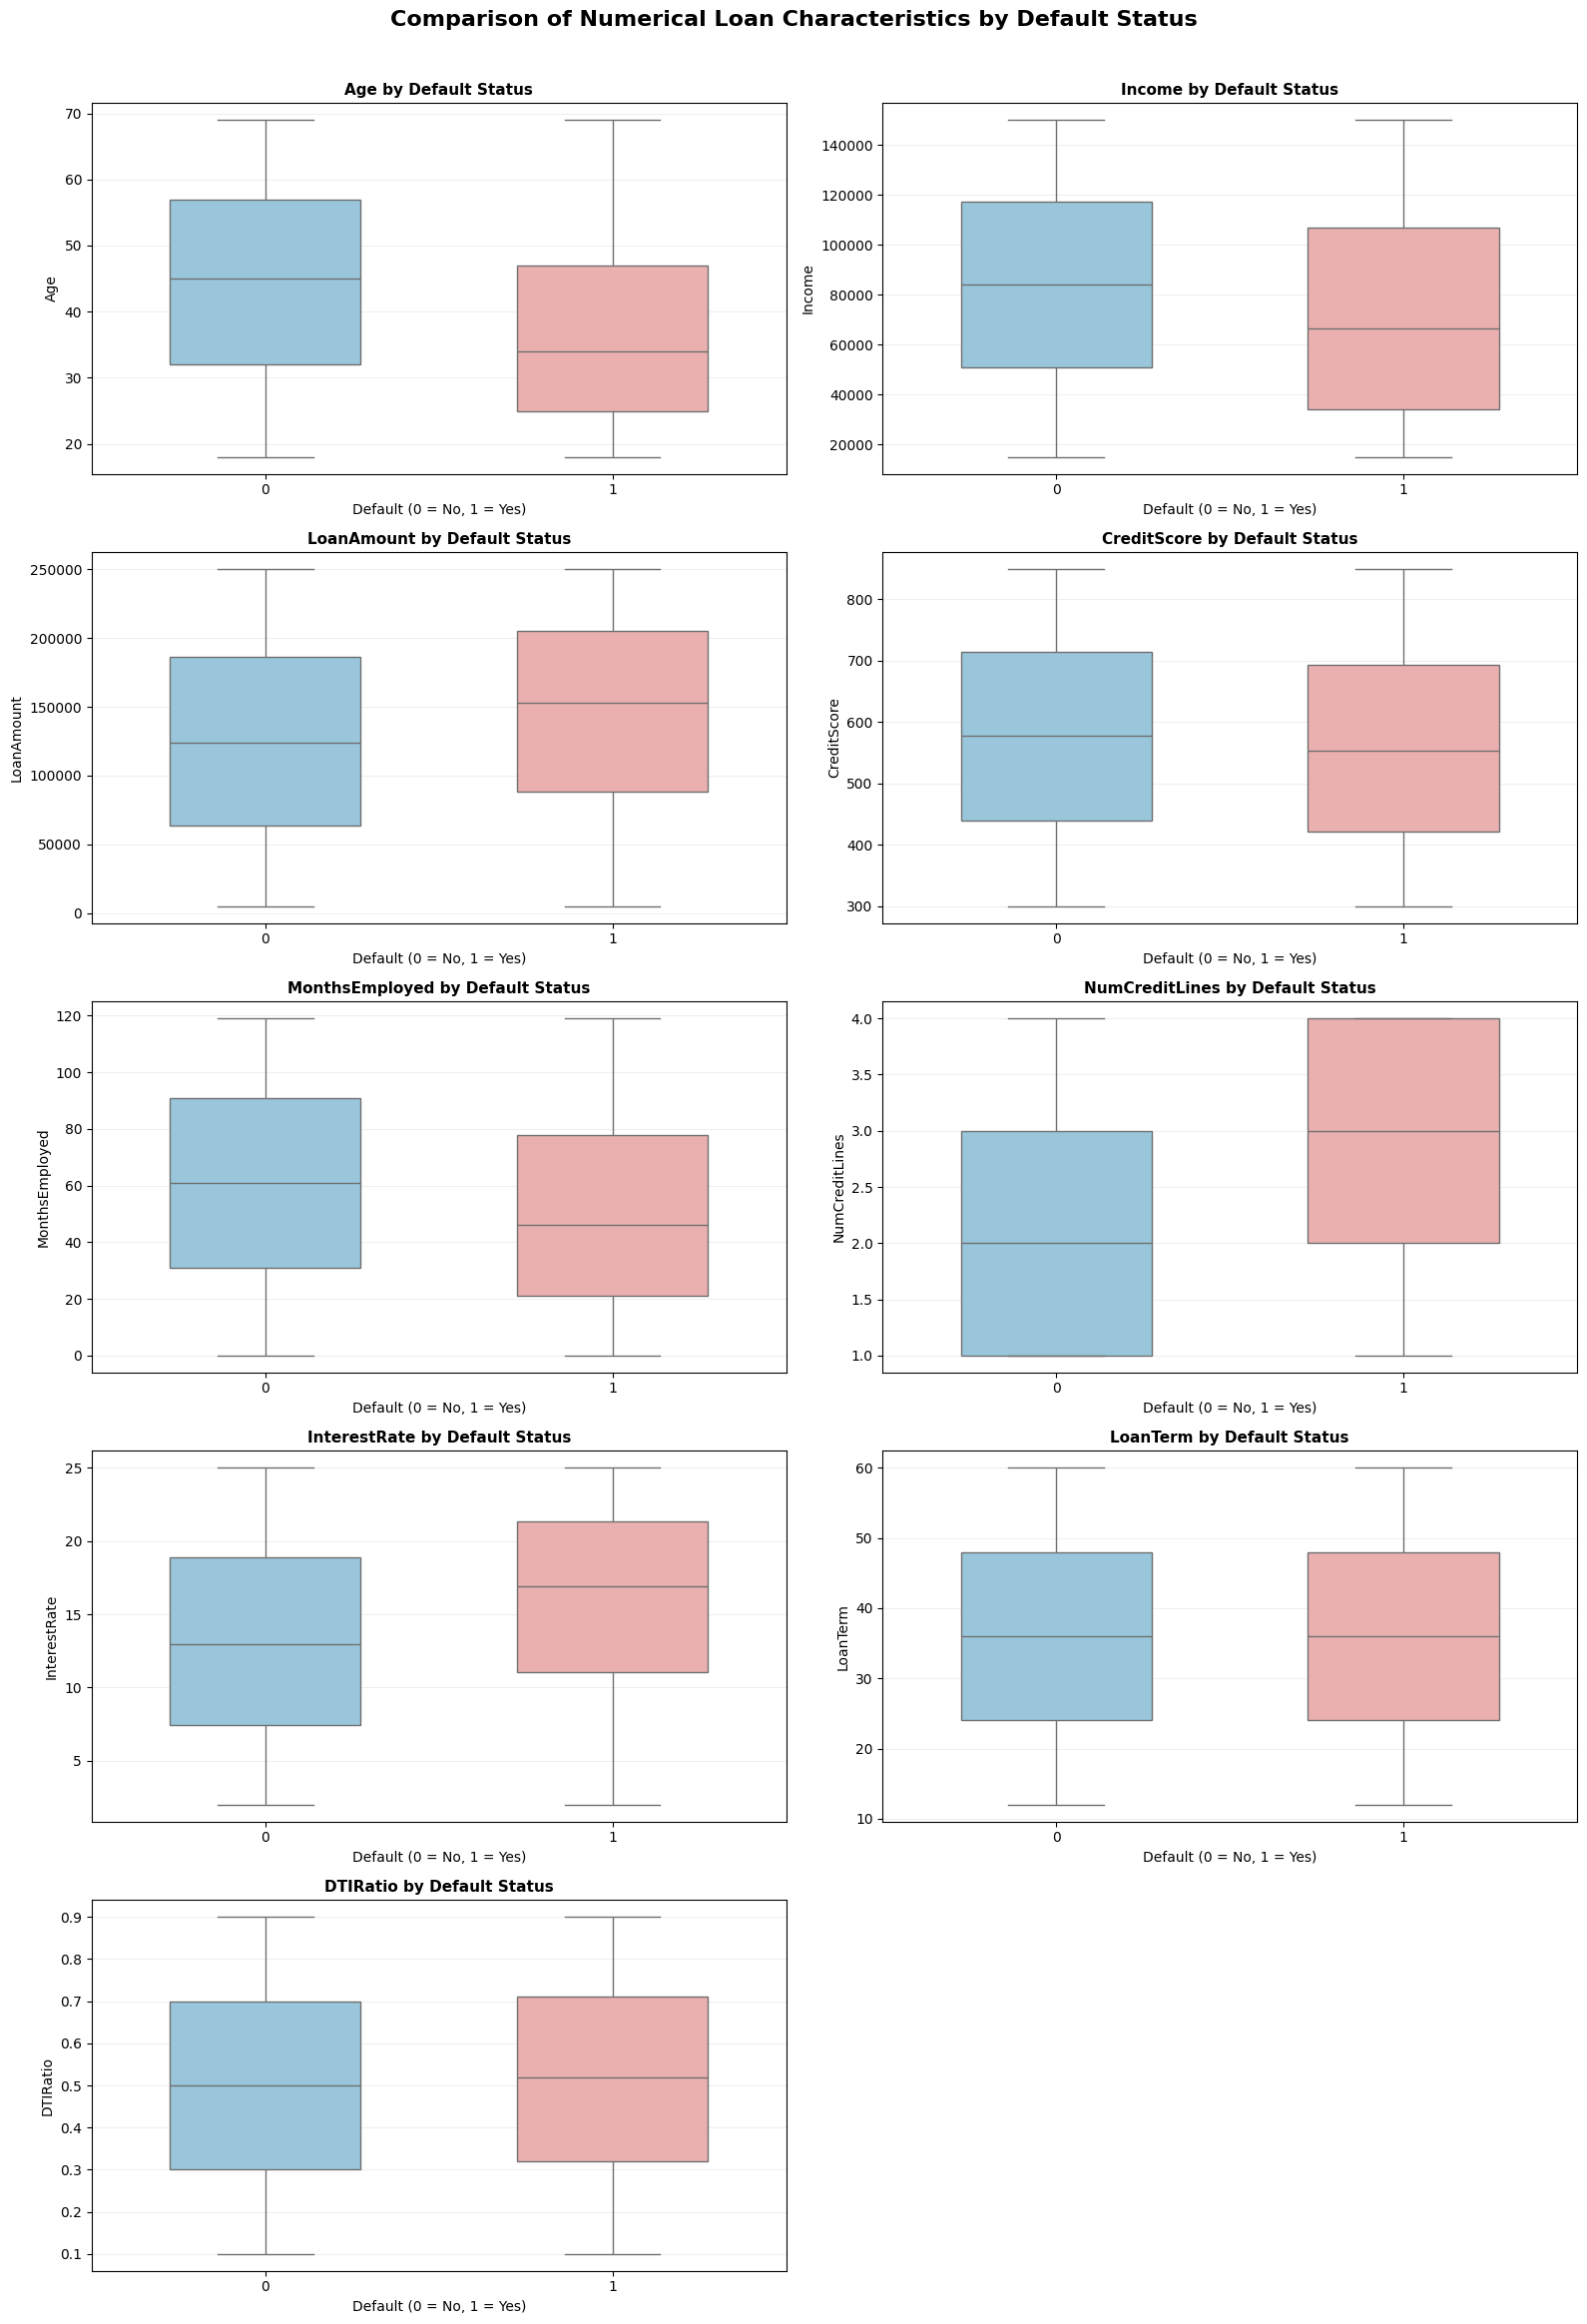

Age                  Income                   LoanAmount            \
          mean median    std      mean   median      std       mean    median   
Default                                                                         
0        44.41   45.0  14.89  83899.17  84237.5  38498.8  125353.66  124236.0   
1        36.56   34.0  13.90  71844.72  66566.0  40785.1  144515.31  152672.0   

                  CreditScore  ... NumCreditLines InterestRate               \
              std        mean  ...            std         mean median   std   
Default                        ...                                            
0        70708.10      576.23  ...           1.12        13.18  12.99  6.61   
1        69547.82      559.29  ...           1.12        15.90  16.93  6.32   

        LoanTerm               DTIRatio               
            mean median    std     mean median   std  
Default                                               
0          36.02   36.0  16.97     0.50   0.50  0.23  
1          36.05   36.0  16.99     0.51   0.52  0.23  

[2 rows x 27 columns]

In [15]:
fig, axes = plt.subplots(5, 2, figsize=(16, 23))
axes = axes.flatten()

palette = {0: '#8ECAE6', 1: '#F4A6A6'}

for i, column in enumerate(numerical_features):

    sns.boxplot(
        data=df,
        x='Default',
        y=column,
        hue='Default',
        palette=palette,
        legend=False,
        showfliers=False,
        width=0.55,
        ax=axes[i]
    )

    axes[i].set_title(
        f'{column} by Default Status',
        fontsize=11,
        fontweight='bold'
    )

    axes[i].set_xlabel('Default (0 = No, 1 = Yes)')
    axes[i].set_ylabel(column)
    axes[i].grid(axis='y', alpha=0.2)

for j in range(len(numerical_features), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    'Comparison of Numerical Loan Characteristics by Default Status',
    fontsize=16,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()



default_comparison = df.groupby('Default')[numerical_features].agg(
    ['mean', 'median', 'std']
).round(2)

display(default_comparison)

**Numerical Features with the Strongest Correlation to Loan Default**

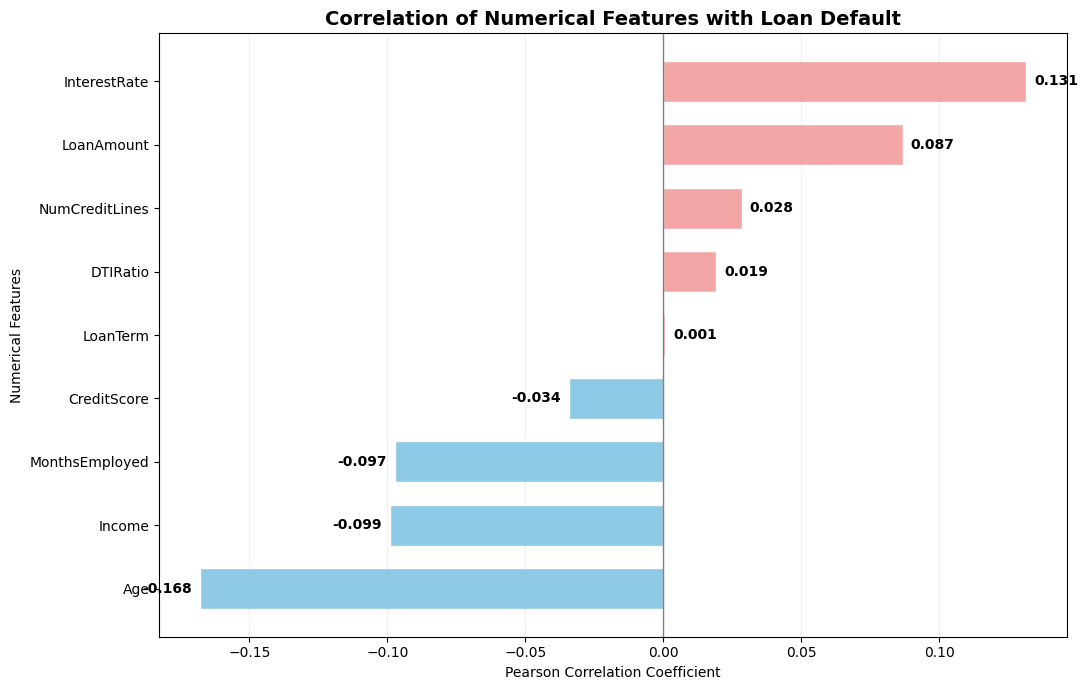


CORRELATION INSIGHTS
Strongest positive correlation:
InterestRate 0.1313

Strongest negative correlation:
Age -0.1678


In [16]:
correlation = (
    df[numerical_features + ['Default']]
    .corr(numeric_only=True)['Default']
    .drop('Default')
    .sort_values()
)

plt.figure(figsize=(11, 7))

colors = [
    '#8ECAE6' if value < 0 else '#F4A6A6'
    for value in correlation.values
]

bars = plt.barh(
    correlation.index,
    correlation.values,
    color=colors,
    edgecolor='white',
    height=0.65
)

for bar, value in zip(bars, correlation.values):
    plt.text(
        value + (0.003 if value >= 0 else -0.003),
        bar.get_y() + bar.get_height()/2,
        f'{value:.3f}',
        va='center',
        ha='left' if value >= 0 else 'right',
        fontsize=10,
        fontweight='bold'
    )

plt.axvline(0, color='grey', linewidth=1)
plt.title(
    'Correlation of Numerical Features with Loan Default',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Numerical Features')
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

print("\nCORRELATION INSIGHTS")
print("=" * 55)
print("Strongest positive correlation:")
print(correlation.idxmax(), round(correlation.max(), 4))

print("\nStrongest negative correlation:")
print(correlation.idxmin(), round(correlation.min(), 4))

**Categorical Feature Distributions**

In [17]:
for column in categorical_features:
    default_rate = df.groupby(column)['Default'].mean().mul(100).sort_values(ascending=False).round(2)
    print(f"\n{column} - Default Rate (%)")
    display(default_rate.to_frame(name='Default Rate (%)'))


Education - Default Rate (%)


,Default Rate (%)
Education,
High School,12.88
Bachelor's,12.10
Master's,10.87
PhD,10.59



EmploymentType - Default Rate (%)


,Default Rate (%)
EmploymentType,
Unemployed,13.55
Part-time,11.97
Self-employed,11.46
Full-time,9.46



MaritalStatus - Default Rate (%)


,Default Rate (%)
MaritalStatus,
Divorced,12.53
Single,11.91
Married,10.40


... (4 outputs left out)


LoanPurpose - Default Rate (%)


,Default Rate (%)
LoanPurpose,
Business,12.33
Auto,11.88
Education,11.84
Other,11.79
Home,10.23



HasCoSigner - Default Rate (%)


,Default Rate (%)
HasCoSigner,
No,12.87
Yes,10.36


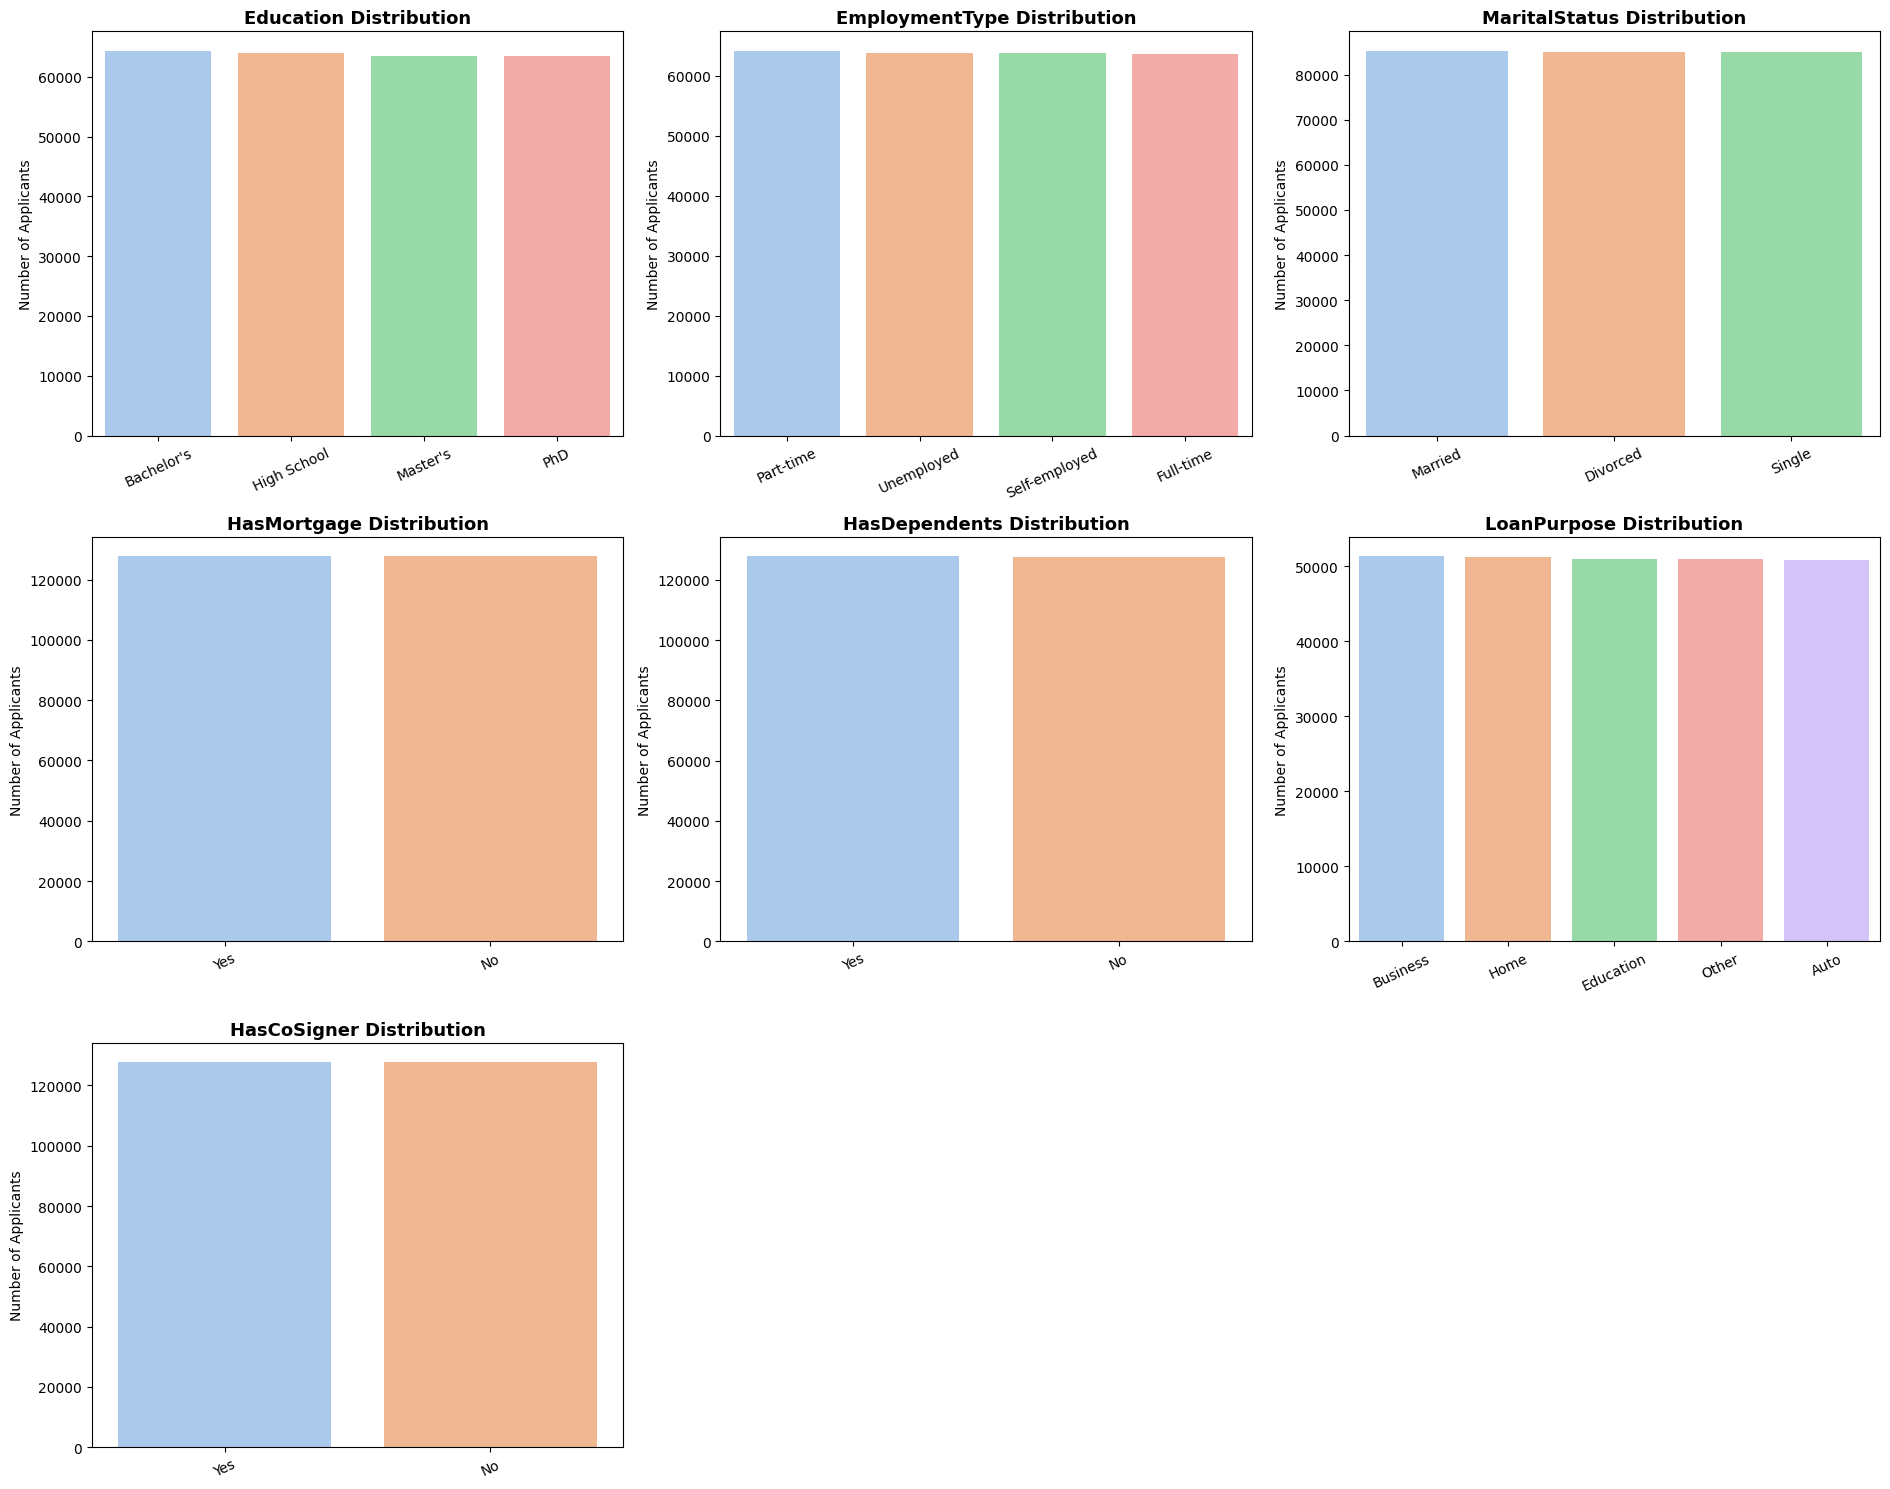


Education
Education
Bachelor's     64366
High School    63903
Master's       63541
PhD            63537
Most common category: Bachelor's

EmploymentType
EmploymentType
Part-time        64161
Unemployed       63824
Self-employed    63706
Full-time        63656
Most common category: Part-time

MaritalStatus
MaritalStatus
Married     85302
Divorced    85033
Single      85012
Most common category: Married

HasMortgage
HasMortgage
Yes    127677
No     127670
Most common category: Yes

HasDependents
HasDependents
Yes    127742
No     127605
Most common category: Yes

LoanPurpose
LoanPurpose
Business     51298
Home         51286
Education    51005
Other        50914
Auto         50844
Most common category: Business

HasCoSigner
HasCoSigner
Yes    127701
No     127646
Most common category: Yes


In [18]:
categorical_features = [
    'Education', 'EmploymentType', 'MaritalStatus',
    'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner'
]

fig, axes = plt.subplots(3, 3, figsize=(19, 15))
axes = axes.flatten()

colours = sns.color_palette("pastel", 7)

for i, col in enumerate(categorical_features):
    counts = df[col].value_counts()
    sns.barplot(
        x=counts.index,
        y=counts.values,
        hue=counts.index,
        palette=colours,
        legend=False,
        ax=axes[i]
    )
    axes[i].set_title(f'{col} Distribution', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Number of Applicants')
    axes[i].tick_params(axis='x', rotation=25)

for j in range(len(categorical_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

for col in categorical_features:
    print(f'\n{col}')
    print(df[col].value_counts().to_string())
    print('Most common category:', df[col].mode()[0])

**Default Rate Across Categorical Features**

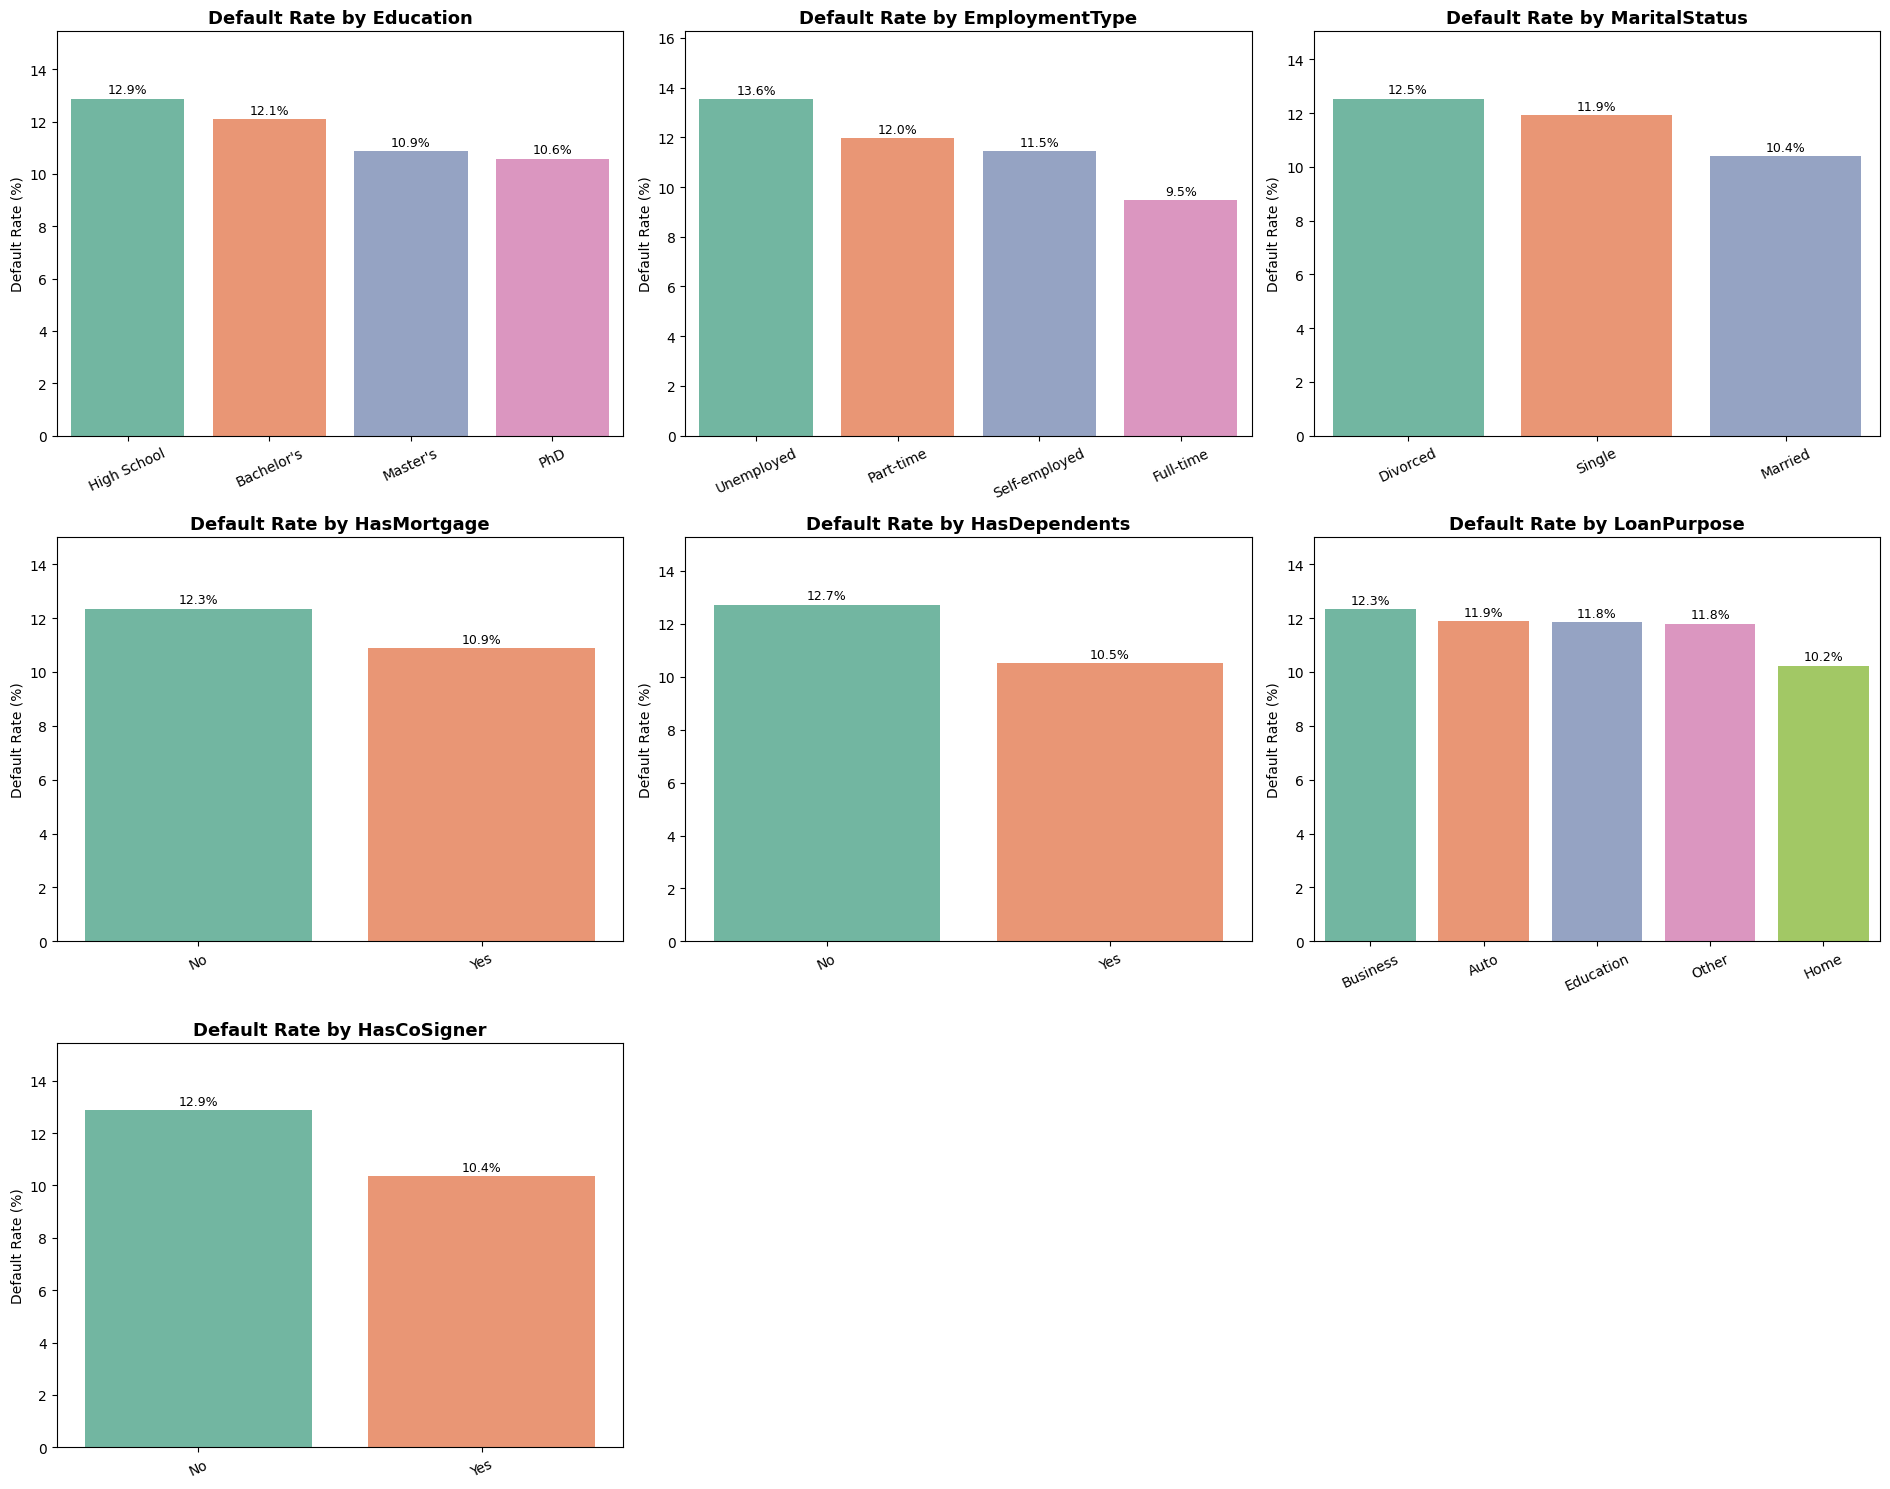


Education
Education
High School    12.88
Bachelor's     12.10
Master's       10.87
PhD            10.59
Highest default rate: High School (12.88%)
Lowest default rate: PhD (10.59%)

EmploymentType
EmploymentType
Unemployed       13.55
Part-time        11.97
Self-employed    11.46
Full-time         9.46
Highest default rate: Unemployed (13.55%)
Lowest default rate: Full-time (9.46%)

MaritalStatus
MaritalStatus
Divorced    12.53
Single      11.91
Married     10.40
Highest default rate: Divorced (12.53%)
Lowest default rate: Married (10.40%)

HasMortgage
HasMortgage
No     12.35
Yes    10.88
Highest default rate: No (12.35%)
Lowest default rate: Yes (10.88%)

HasDependents
HasDependents
No     12.72
Yes    10.50
Highest default rate: No (12.72%)
Lowest default rate: Yes (10.50%)

LoanPurpose
LoanPurpose
Business     12.33
Auto         11.88
Education    11.84
Other        11.79
Home         10.23
Highest default rate: Business (12.33%)
Lowest default rate: Home (10.23%)

HasCoSigner
Has

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(19, 15))
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    rate = df.groupby(col, observed=False)['Default'].mean().mul(100).sort_values(ascending=False)

    sns.barplot(
        x=rate.index,
        y=rate.values,
        hue=rate.index,
        palette='Set2',
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f'Default Rate by {col}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Default Rate (%)')
    axes[i].tick_params(axis='x', rotation=25)
    axes[i].set_ylim(0, max(15, rate.max() * 1.2))

    for j, value in enumerate(rate.values):
        axes[i].text(j, value + 0.2, f'{value:.1f}%', ha='center', fontsize=9)

for j in range(len(categorical_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

for col in categorical_features:
    rates = df.groupby(col, observed=False)['Default'].mean().mul(100)
    print(f'\n{col}')
    print(rates.sort_values(ascending=False).round(2).to_string())
    print('Highest default rate:', rates.idxmax(), f'({rates.max():.2f}%)')
    print('Lowest default rate:', rates.idxmin(), f'({rates.min():.2f}%)')

**Applicant Composition by Default Status**

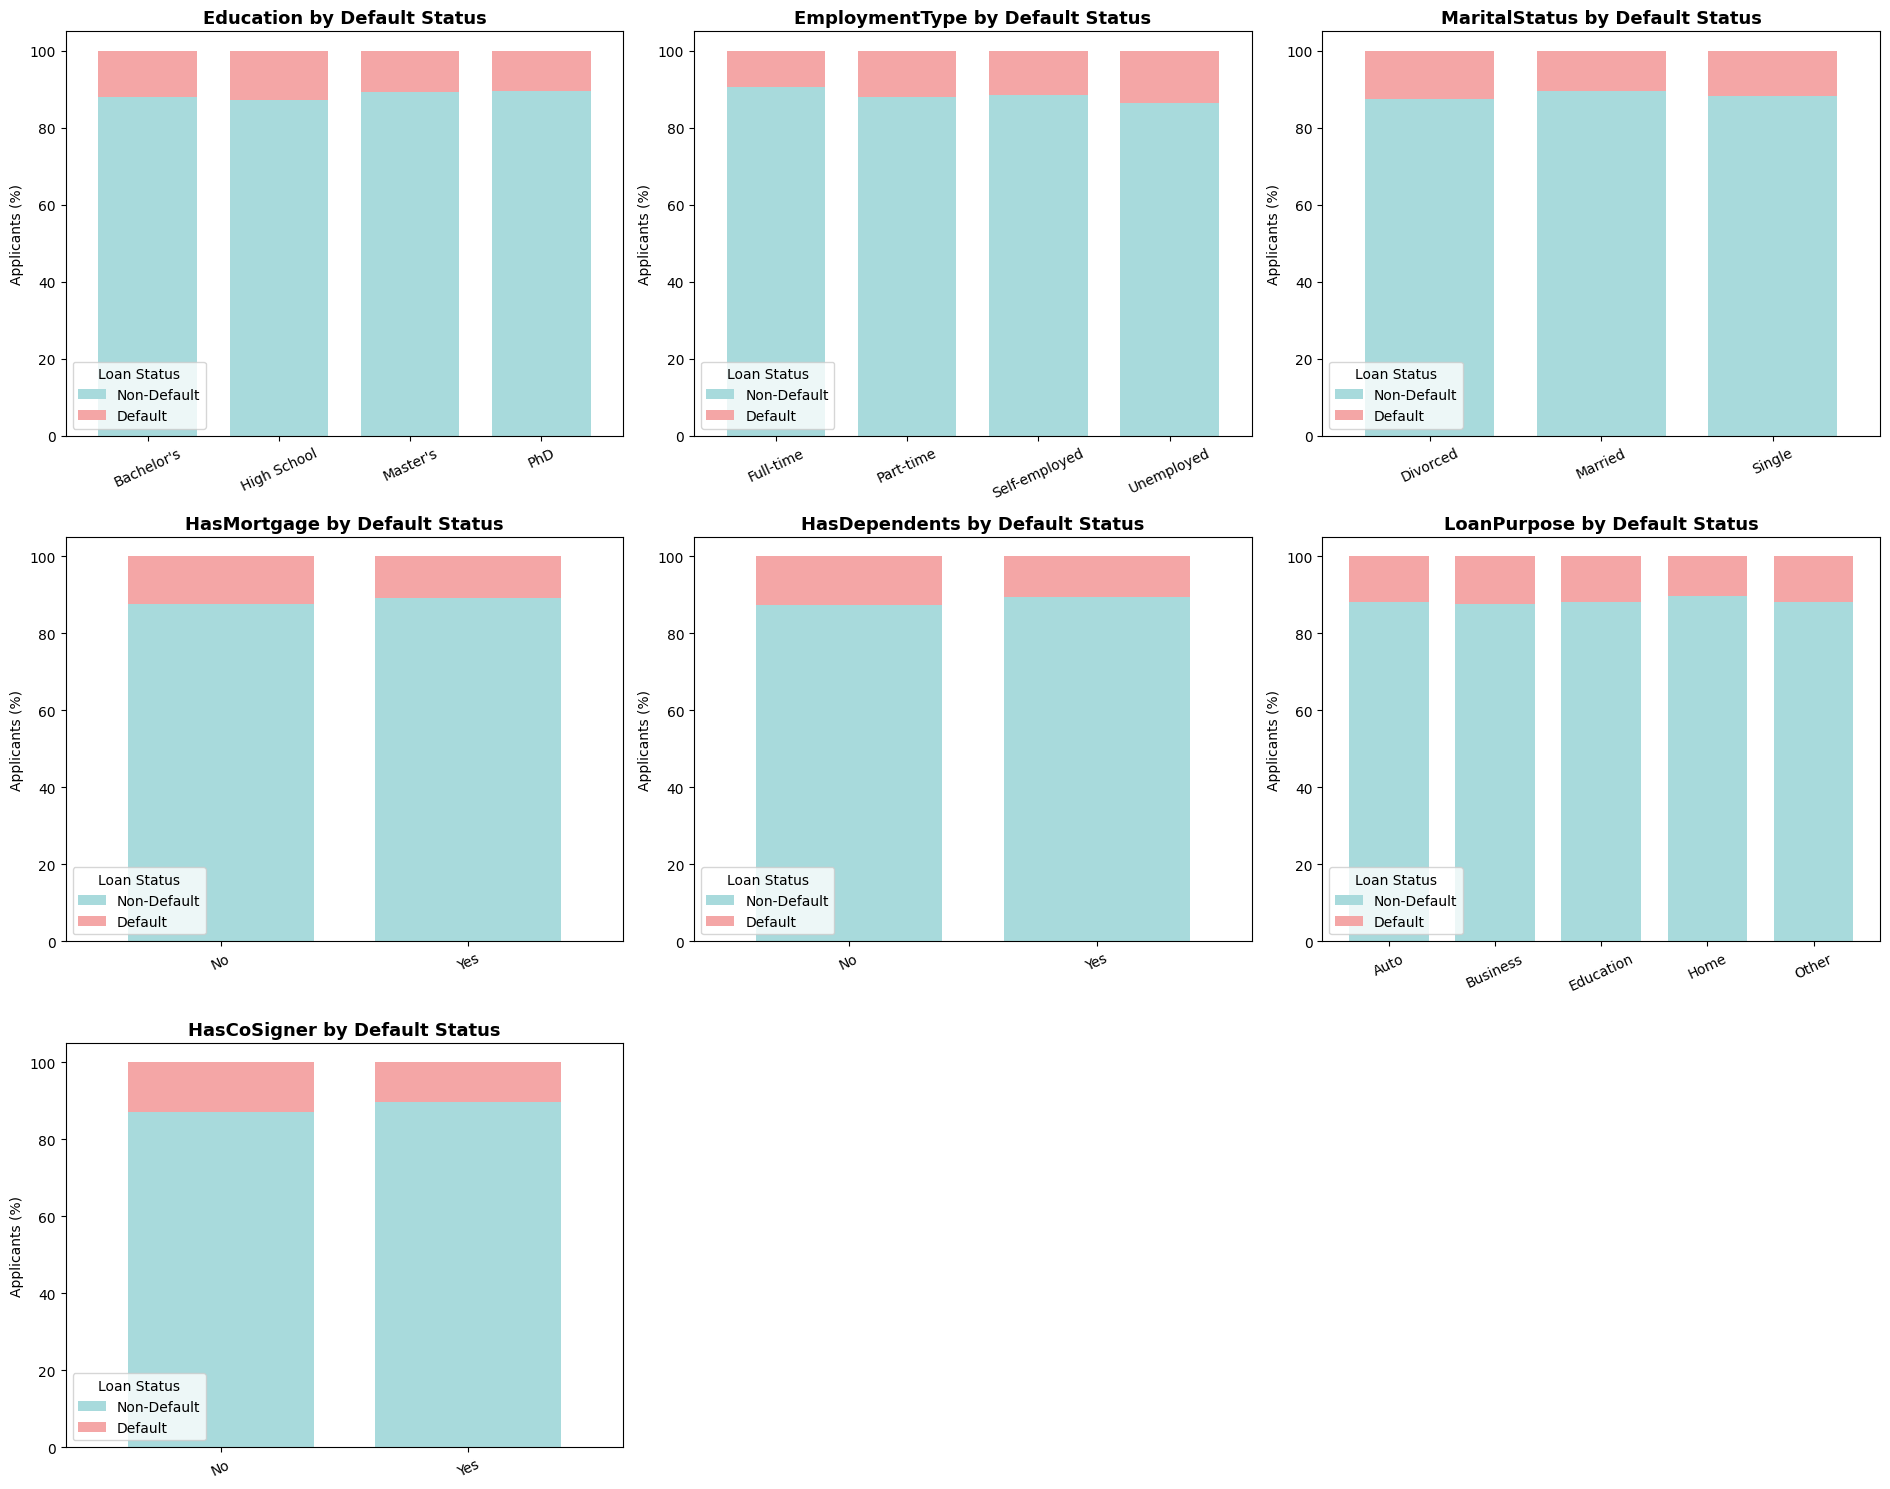


Education
Default          0      1
Education                
Bachelor's   87.90  12.10
High School  87.12  12.88
Master's     89.13  10.87
PhD          89.41  10.59

EmploymentType
Default             0      1
EmploymentType              
Full-time       90.54   9.46
Part-time       88.03  11.97
Self-employed   88.54  11.46
Unemployed      86.45  13.55

MaritalStatus
Default            0      1
MaritalStatus              
Divorced       87.47  12.53
Married        89.60  10.40
Single         88.09  11.91

HasMortgage
Default          0      1
HasMortgage              
No           87.65  12.35
Yes          89.12  10.88

HasDependents
Default            0      1
HasDependents              
No             87.28  12.72
Yes            89.50  10.50

LoanPurpose
Default          0      1
LoanPurpose              
Auto         88.12  11.88
Business     87.67  12.33
Education    88.16  11.84
Home         89.77  10.23
Other        88.21  11.79

HasCoSigner
Default          0      1
HasCoSigne

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(19, 15))
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    composition = pd.crosstab(df[col], df['Default'], normalize='index') * 100

    composition.plot(
        kind='bar',
        stacked=True,
        color=['#A8DADC', '#F4A6A6'],
        ax=axes[i],
        width=0.75
    )

    axes[i].set_title(f'{col} by Default Status', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Applicants (%)')
    axes[i].legend(['Non-Default', 'Default'], title='Loan Status')
    axes[i].tick_params(axis='x', rotation=25)

for j in range(len(categorical_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

for col in categorical_features:
    composition = pd.crosstab(df[col], df['Default'], normalize='index') * 100
    print(f'\n{col}')
    print(composition.round(2).to_string())

**Numerical Feature Relationships**

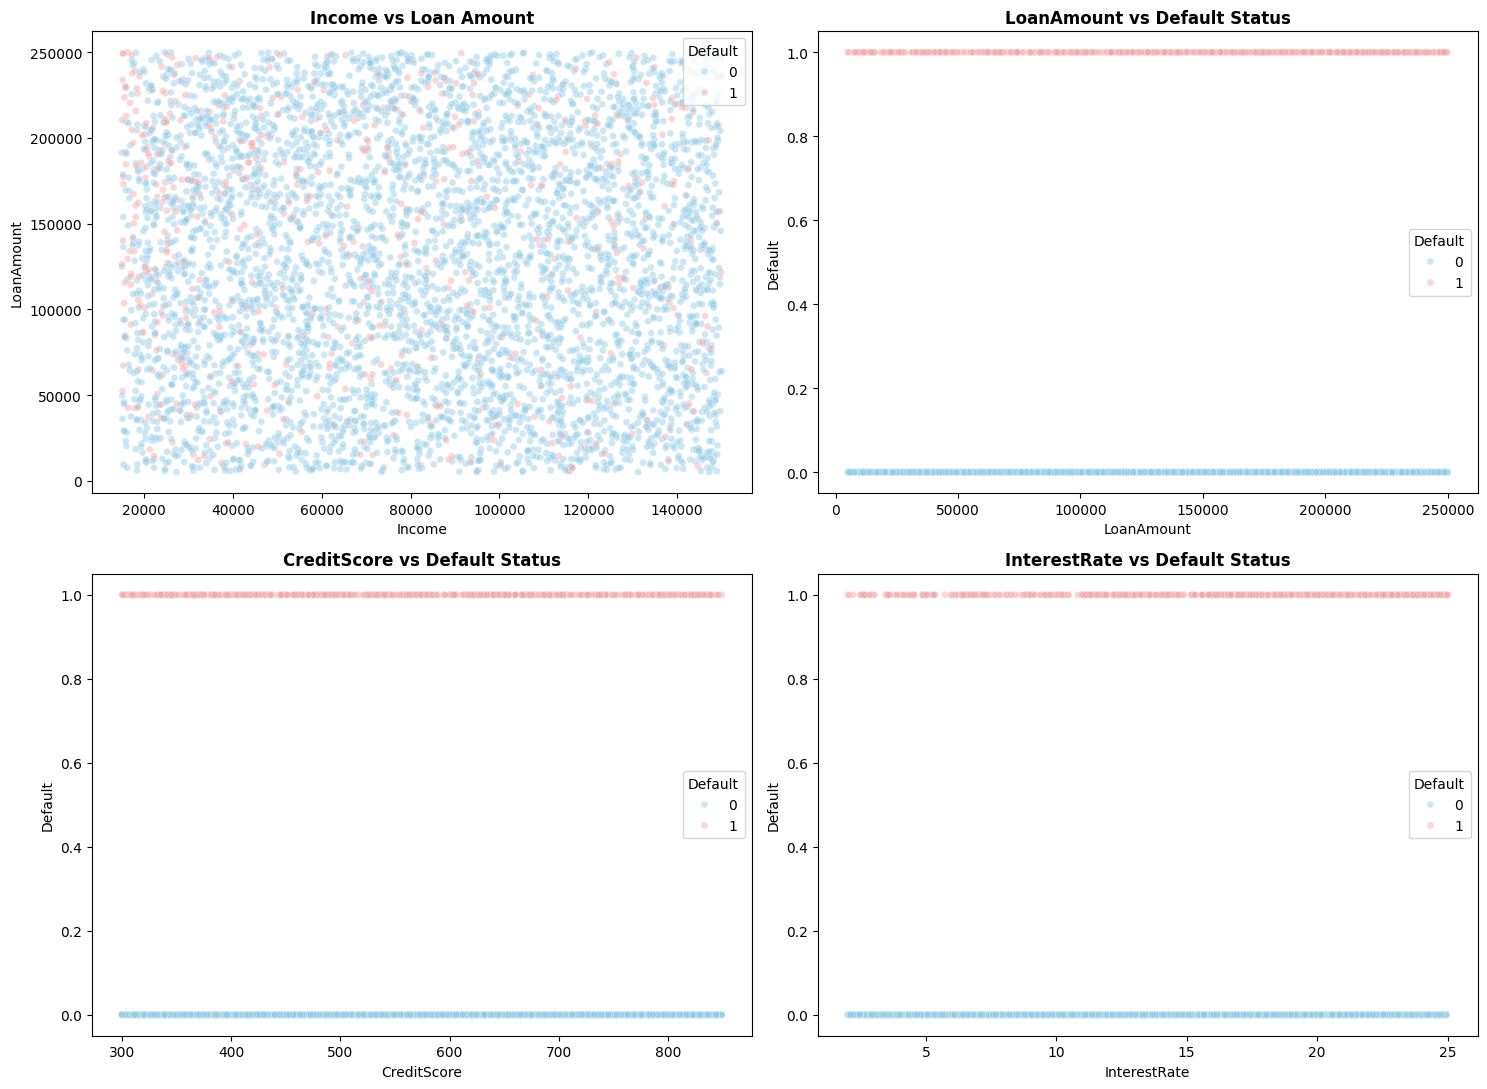

NUMERICAL RELATIONSHIP INSIGHTS

Income
Non-default average: 83,899.17
Default average:     71,844.72
Difference:          -12,054.44

LoanAmount
Non-default average: 125,353.66
Default average:     144,515.31
Difference:          19,161.66

CreditScore
Non-default average: 576.23
Default average:     559.29
Difference:          -16.95

InterestRate
Non-default average: 13.18
Default average:     15.90
Difference:          2.72


In [21]:
selected_features = ['Income', 'LoanAmount', 'CreditScore', 'InterestRate']

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(selected_features):
    sns.scatterplot(
        data=df.sample(min(5000, len(df)), random_state=42),
        x=col,
        y='LoanAmount' if col == 'Income' else 'Default',
        hue='Default',
        palette={0: '#8ECAE6', 1: '#F4A6A6'},
        alpha=0.45,
        s=25,
        ax=axes[i]
    )

    axes[i].set_title(
        f'{col} vs {"Loan Amount" if col == "Income" else "Default Status"}',
        fontsize=12,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

print('NUMERICAL RELATIONSHIP INSIGHTS')
print('=' * 60)

for col in selected_features:
    group_means = df.groupby('Default')[col].mean()
    difference = group_means[1] - group_means[0]

    print(f'\n{col}')
    print(f'Non-default average: {group_means[0]:,.2f}')
    print(f'Default average:     {group_means[1]:,.2f}')
    print(f'Difference:          {difference:,.2f}')

**Loan Amount and Income Relationship by Default Status**

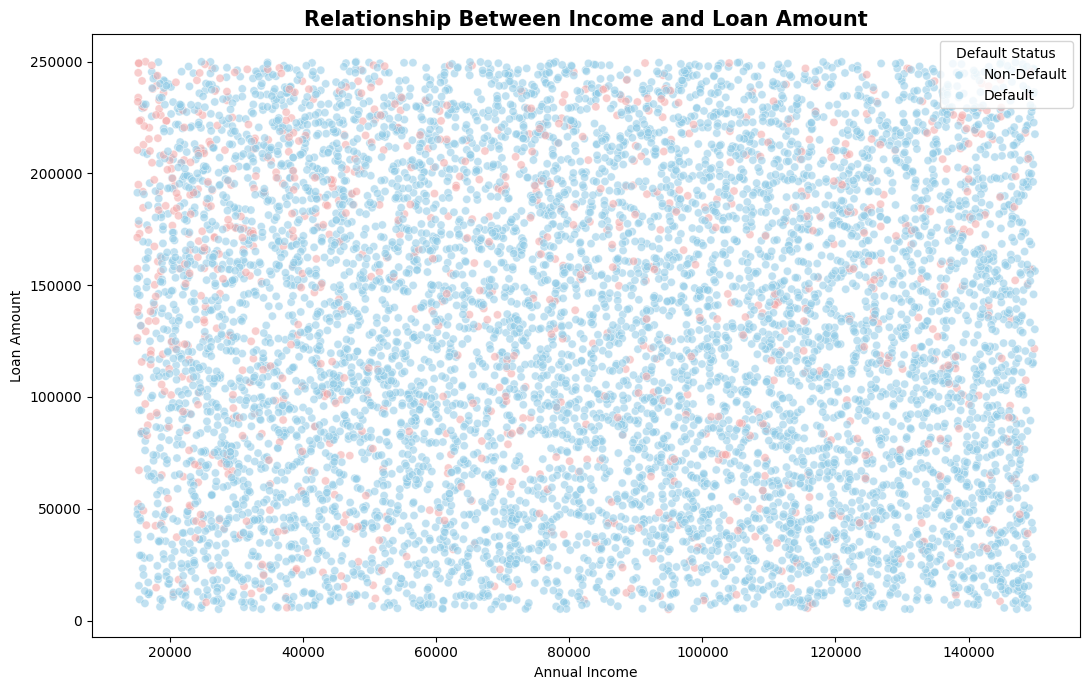

INCOME AND LOAN AMOUNT INSIGHTS

Non-Default applicants
Average income:      83,899.17
Average loan amount: 125,353.66
Average loan-to-income ratio: 2.036

Default applicants
Average income:      71,844.72
Average loan amount: 144,515.31
Average loan-to-income ratio: 3.253

Overall income-loan amount correlation: -0.0009


In [22]:
sample_df = df.sample(min(8000, len(df)), random_state=42)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=sample_df,
    x='Income',
    y='LoanAmount',
    hue='Default',
    palette={0: '#8ECAE6', 1: '#F4A6A6'},
    alpha=0.55,
    s=35
)

plt.title('Relationship Between Income and Loan Amount', fontsize=15, fontweight='bold')
plt.xlabel('Annual Income')
plt.ylabel('Loan Amount')
plt.legend(title='Default Status', labels=['Non-Default', 'Default'])
plt.tight_layout()
plt.show()

print('INCOME AND LOAN AMOUNT INSIGHTS')
print('=' * 60)

for status, group in df.groupby('Default'):
    print(f'\n{"Default" if status == 1 else "Non-Default"} applicants')
    print(f'Average income:      {group["Income"].mean():,.2f}')
    print(f'Average loan amount: {group["LoanAmount"].mean():,.2f}')
    print(f'Average loan-to-income ratio: {(group["LoanAmount"] / group["Income"]).mean():.3f}')

print('\nOverall income-loan amount correlation:',
      round(df['Income'].corr(df['LoanAmount']), 4))

**Categorical Feature Association Analysis**

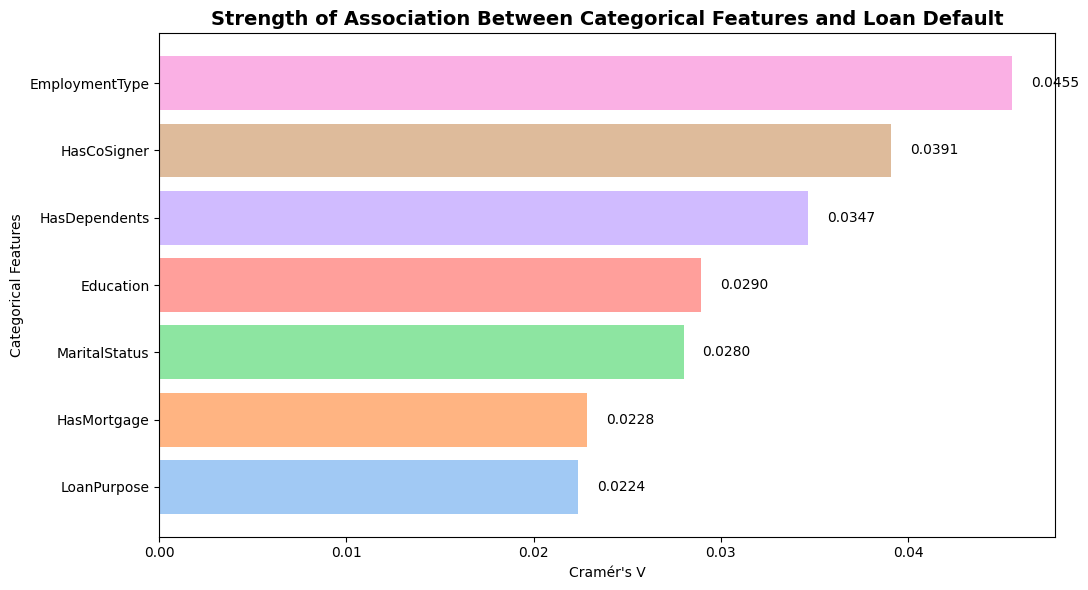

CHI-SQUARE AND CRAMÉR'S V RESULTS
       Feature  Chi-Square  P-Value  Cramers V
   LoanPurpose  127.934225 0.000000   0.022383
   HasMortgage  133.252006 0.000000   0.022844
 MaritalStatus  200.361136 0.000000   0.028012
     Education  214.018983 0.000000   0.028951
 HasDependents  306.850609 0.000000   0.034666
   HasCoSigner  390.305046 0.000000   0.039096
EmploymentType  529.744928 0.000000   0.045548


In [23]:
from scipy.stats import chi2_contingency
import numpy as np

association_results = []

for col in categorical_features:
    contingency_table = pd.crosstab(df[col], df['Default'])
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum()
    minimum_dimension = min(contingency_table.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * minimum_dimension))

    association_results.append({
        'Feature': col,
        'Chi-Square': chi2,
        'P-Value': p_value,
        'Cramers V': cramers_v
    })

association_df = pd.DataFrame(association_results)
association_df = association_df.sort_values('Cramers V', ascending=True)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    association_df['Feature'],
    association_df['Cramers V'],
    color=sns.color_palette('pastel', len(association_df))
)

for bar, value in zip(bars, association_df['Cramers V']):
    plt.text(
        value + 0.001,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.4f}',
        va='center',
        fontsize=10
    )

plt.title('Strength of Association Between Categorical Features and Loan Default',
          fontsize=14, fontweight='bold')
plt.xlabel("Cramér's V")
plt.ylabel('Categorical Features')
plt.tight_layout()
plt.show()

print('CHI-SQUARE AND CRAMÉR\'S V RESULTS')
print('=' * 75)
print(association_df.to_string(index=False, float_format=lambda x: f'{x:.6f}'))

Correlation Analysis

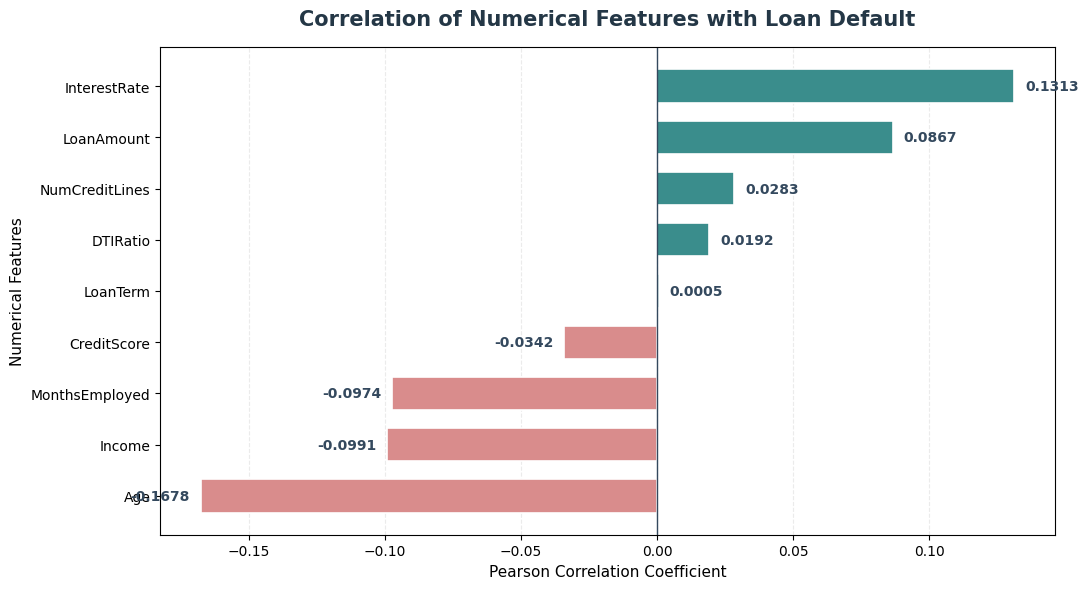

NUMERICAL FEATURE CORRELATION INSIGHTS
Strongest positive correlation: InterestRate (0.1313)
Strongest negative correlation: Age (-0.1678)
Average absolute correlation: 0.0738

Complete correlation values:


,Correlation with Default
Age,-0.1678
InterestRate,0.1313
Income,-0.0991
MonthsEmployed,-0.0974
LoanAmount,0.0867
CreditScore,-0.0342
NumCreditLines,0.0283
DTIRatio,0.0192
LoanTerm,0.0005


In [24]:
correlation_matrix = df[numerical_features + ['Default']].corr()

default_correlation = (
    correlation_matrix['Default']
    .drop('Default')
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 6))

colours = [
    '#D98C8C' if value < 0 else '#3A8D8C'
    for value in default_correlation.values
]

bars = plt.barh(
    default_correlation.index,
    default_correlation.values,
    color=colours,
    edgecolor='#FFFFFF',
    linewidth=1.2,
    height=0.65
)

plt.axvline(0, color='#34495E', linewidth=1)

for bar, value in zip(bars, default_correlation.values):
    offset = 0.004 if value >= 0 else -0.004
    plt.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.4f}',
        va='center',
        ha='left' if value >= 0 else 'right',
        fontsize=10,
        fontweight='bold',
        color='#34495E'
    )

plt.title(
    'Correlation of Numerical Features with Loan Default',
    fontsize=15,
    fontweight='bold',
    pad=16,
    color='#243746'
)

plt.xlabel('Pearson Correlation Coefficient', fontsize=11)
plt.ylabel('Numerical Features', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.25)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()

print('NUMERICAL FEATURE CORRELATION INSIGHTS')
print('=' * 60)

print(f'Strongest positive correlation: {default_correlation.idxmax()} '
      f'({default_correlation.max():.4f})')

print(f'Strongest negative correlation: {default_correlation.idxmin()} '
      f'({default_correlation.min():.4f})')

print(f'Average absolute correlation: {default_correlation.abs().mean():.4f}')

print('\nComplete correlation values:')
display(
    default_correlation.sort_values(
        key=lambda x: x.abs(),
        ascending=False
    ).to_frame(name='Correlation with Default').style
    .format('{:.4f}')
    .background_gradient(cmap='YlGnBu')
)

Correlation Heatmap

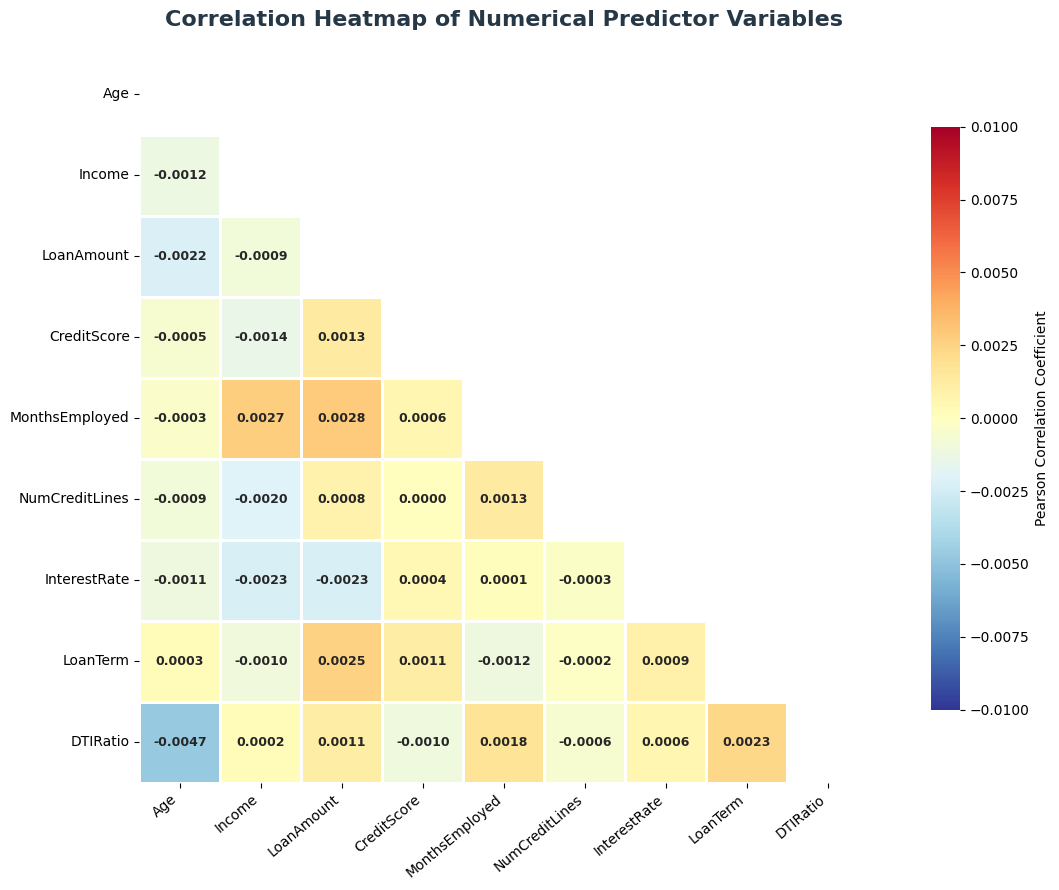

TOP NUMERICAL FEATURE RELATIONSHIPS


,Feature 1,Feature 2,Correlation,Absolute Correlation
7,Age,DTIRatio,-0.0047,0.0047
16,LoanAmount,MonthsEmployed,0.0028,0.0028
10,Income,MonthsEmployed,0.0027,0.0027
19,LoanAmount,LoanTerm,0.0025,0.0025
12,Income,InterestRate,-0.0023,0.0023
18,LoanAmount,InterestRate,-0.0023,0.0023
35,LoanTerm,DTIRatio,0.0023,0.0023
1,Age,LoanAmount,-0.0022,0.0022
11,Income,NumCreditLines,-0.0020,0.0020
29,MonthsEmployed,DTIRatio,0.0018,0.0018



HIGH CORRELATION PAIRS (|r| >= 0.70)
No highly correlated numerical feature pairs identified.


In [25]:
correlation_matrix = df[numerical_features].corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt='.4f',
    cmap='RdYlBu_r',
    center=0,
    vmin=-0.01,
    vmax=0.01,
    linewidths=1,
    linecolor='white',
    square=True,
    annot_kws={'size': 9, 'weight': 'bold'},
    cbar_kws={
        'shrink': 0.8,
        'label': 'Pearson Correlation Coefficient'
    }
)

plt.title(
    'Correlation Heatmap of Numerical Predictor Variables',
    fontsize=16,
    fontweight='bold',
    pad=20,
    color='#263746'
)

plt.xticks(rotation=40, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

strong_correlations = (
    upper_triangle.stack()
    .reset_index()
)

strong_correlations.columns = [
    'Feature 1',
    'Feature 2',
    'Correlation'
]

strong_correlations['Absolute Correlation'] = (
    strong_correlations['Correlation'].abs()
)

strong_correlations = strong_correlations.sort_values(
    'Absolute Correlation',
    ascending=False
)

print('TOP NUMERICAL FEATURE RELATIONSHIPS')
print('=' * 65)

display(
    strong_correlations.head(10).style
    .format({
        'Correlation': '{:.4f}',
        'Absolute Correlation': '{:.4f}'
    })
    .background_gradient(
        subset=['Absolute Correlation'],
        cmap='YlGnBu'
    )
)

print('\nHIGH CORRELATION PAIRS (|r| >= 0.70)')
print('=' * 65)

high_corr = strong_correlations[
    strong_correlations['Absolute Correlation'] >= 0.70
]

if high_corr.empty:
    print('No highly correlated numerical feature pairs identified.')
else:
    display(high_corr.round(4))

**Outlier Detection Using IQR**



IQR OUTLIER DETECTION RESULTS


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Age,31.00,56.00,25.00,-6.50,93.50,0,0.00%
1,Income,"48,825.50","116,219.00","67,393.50","-52,264.75","217,309.25",0,0.00%
2,LoanAmount,"66,156.00","188,985.00","122,829.00","-118,087.50","373,228.50",0,0.00%
3,CreditScore,437.00,712.00,275.00,24.50,"1,124.50",0,0.00%
4,MonthsEmployed,30.00,90.00,60.00,-60.00,180.00,0,0.00%
5,NumCreditLines,2.00,3.00,1.00,0.50,4.50,0,0.00%
6,InterestRate,7.77,19.25,11.48,-9.45,36.47,0,0.00%
7,LoanTerm,24.00,48.00,24.00,-12.00,84.00,0,0.00%
8,DTIRatio,0.30,0.70,0.40,-0.30,1.30,0,0.00%


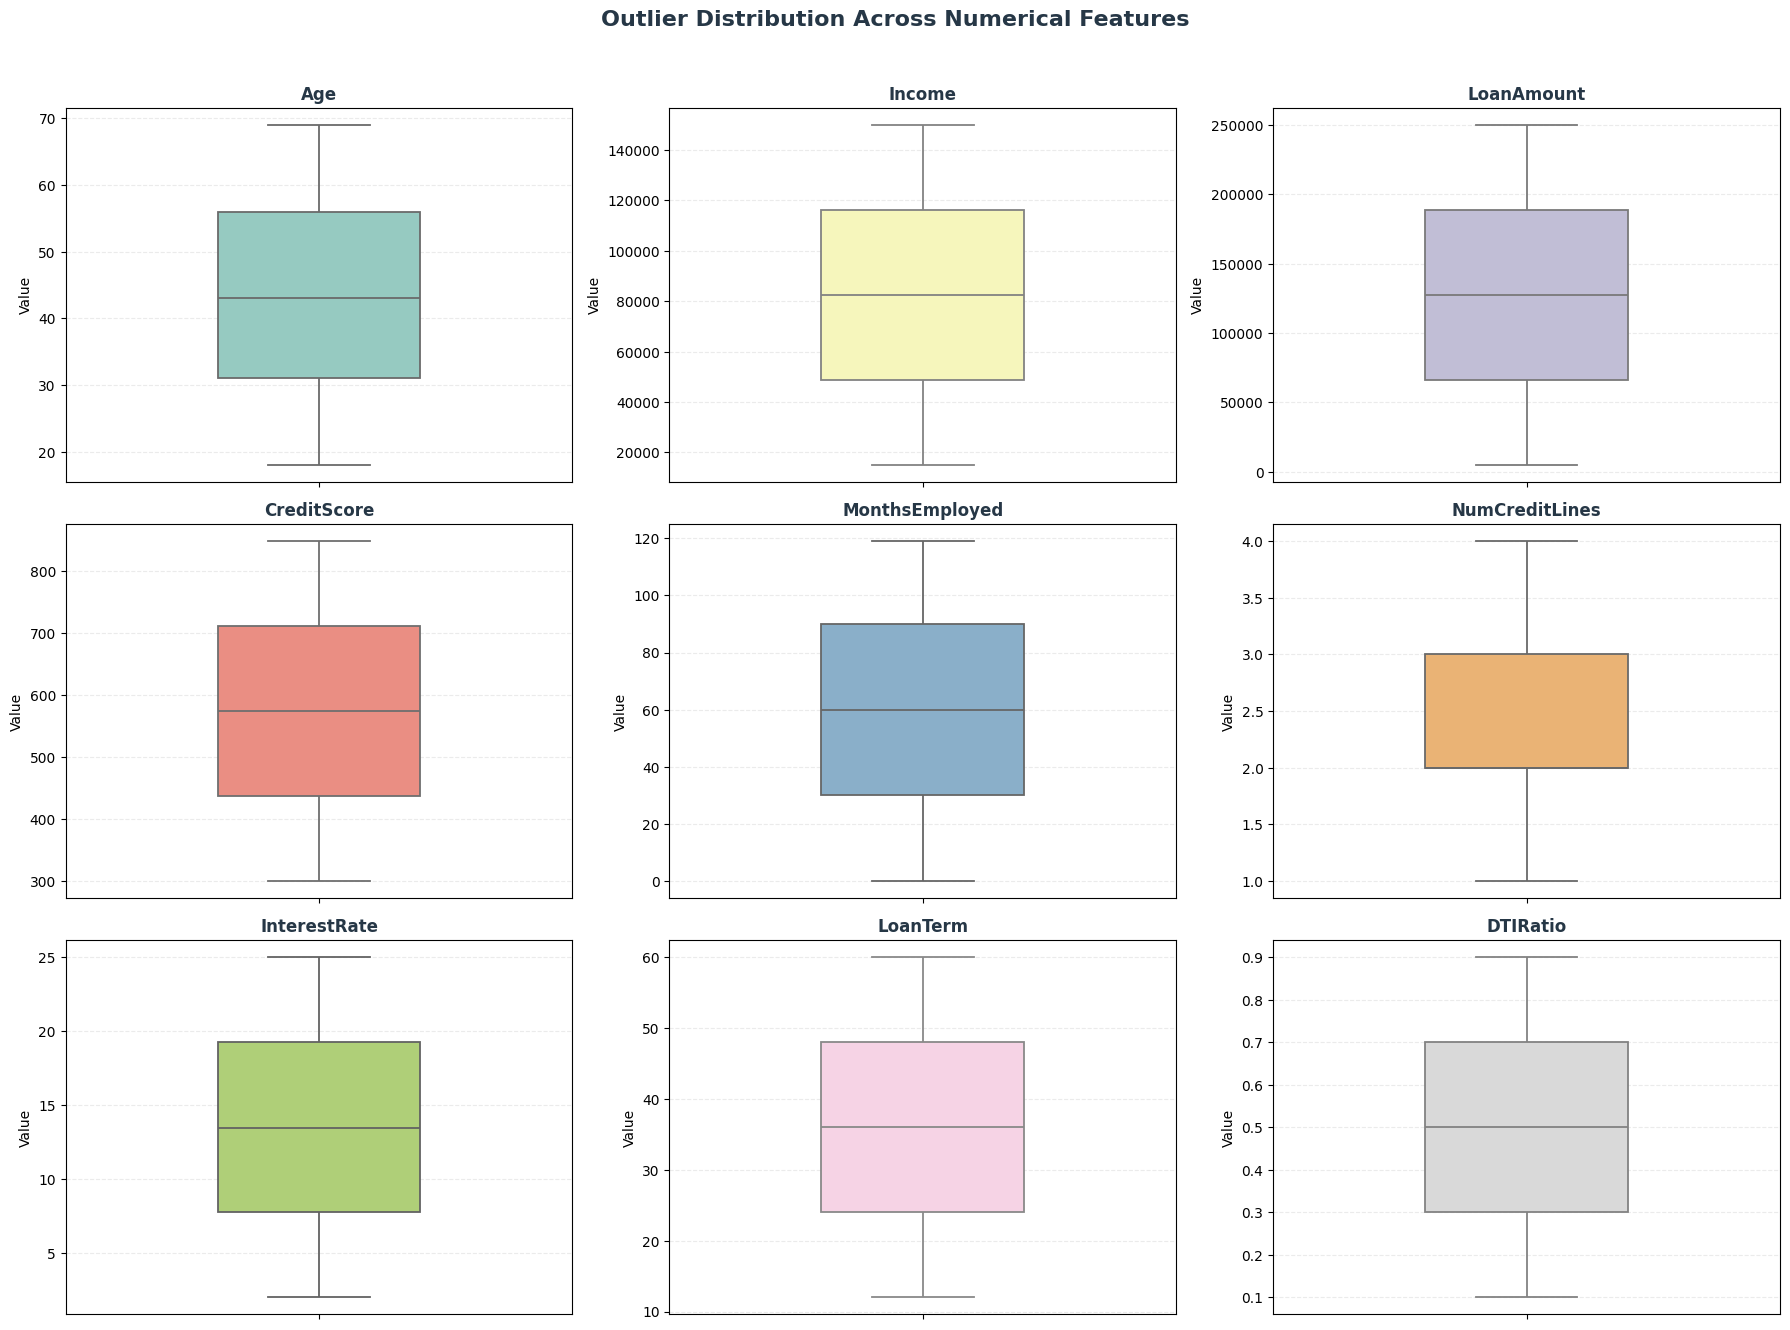


OUTLIER SUMMARY
Age: 0 outliers (0.00%)
Income: 0 outliers (0.00%)
LoanAmount: 0 outliers (0.00%)
CreditScore: 0 outliers (0.00%)
MonthsEmployed: 0 outliers (0.00%)
NumCreditLines: 0 outliers (0.00%)
InterestRate: 0 outliers (0.00%)
LoanTerm: 0 outliers (0.00%)
DTIRatio: 0 outliers (0.00%)

Total unique records containing at least one numerical outlier: 0
Percentage of dataset containing at least one numerical outlier: 0.00%


In [26]:
iqr_results = []

for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    iqr_results.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (len(outliers) / len(df)) * 100
    })

iqr_df = pd.DataFrame(iqr_results)

print('IQR OUTLIER DETECTION RESULTS')
print('=' * 100)

display(
    iqr_df.style
    .format({
        'Q1': '{:,.2f}',
        'Q3': '{:,.2f}',
        'IQR': '{:,.2f}',
        'Lower Bound': '{:,.2f}',
        'Upper Bound': '{:,.2f}',
        'Outlier Count': '{:,.0f}',
        'Outlier Percentage': '{:.2f}%'
    })
    .background_gradient(
        subset=['Outlier Percentage'],
        cmap='YlOrRd'
    )
)

fig, axes = plt.subplots(3, 3, figsize=(18, 13))
axes = axes.flatten()

box_colours = sns.color_palette('Set3', len(numerical_features))

for i, col in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        y=col,
        color=box_colours[i],
        width=0.4,
        linewidth=1.3,
        flierprops={
            'marker': 'o',
            'markersize': 2.5,
            'markerfacecolor': '#D95F59',
            'markeredgecolor': '#D95F59',
            'alpha': 0.35
        },
        ax=axes[i]
    )

    axes[i].set_title(
        f'{col}',
        fontsize=12,
        fontweight='bold',
        color='#263746'
    )

    axes[i].set_xlabel('')
    axes[i].set_ylabel('Value')
    axes[i].grid(axis='y', linestyle='--', alpha=0.25)

plt.suptitle(
    'Outlier Distribution Across Numerical Features',
    fontsize=16,
    fontweight='bold',
    color='#263746',
    y=1.02
)

plt.tight_layout()
plt.show()

print('\nOUTLIER SUMMARY')
print('=' * 65)

total_outlier_records = set()

for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_indices = df.index[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    total_outlier_records.update(outlier_indices)

    print(
        f'{col}: {len(outlier_indices):,} outliers '
        f'({len(outlier_indices) / len(df) * 100:.2f}%)'
    )

print('\nTotal unique records containing at least one numerical outlier:',
      f'{len(total_outlier_records):,}')

print('Percentage of dataset containing at least one numerical outlier:',
      f'{len(total_outlier_records) / len(df) * 100:.2f}%')

No numerical variable is capped, winsorised or removed based on the IQR flags above. In a credit-risk
context, borrowers at the extremes of income, loan amount, interest rate or DTI are often exactly the
high-risk cases the model needs to learn from, so removing them would discard genuine signal rather than
noise. All flagged values are retained, and tree-based models (Decision Tree, Random Forest, XGBoost,
LightGBM) used later in this notebook are not sensitive to outliers in the way linear models can be.

# **Feature Engineering**

**Create Loan-to-Income Ratio**

In [27]:
df['LoanToIncomeRatio'] = np.where(
    df['Income'] > 0,
    df['LoanAmount'] / df['Income'],
    np.nan
)

print('LoanToIncomeRatio created successfully.')

display(
    df[['Income', 'LoanAmount', 'LoanToIncomeRatio']].head(10)
)

print('\nFEATURE VALIDATION')
print('=' * 55)
print('Missing values:', df['LoanToIncomeRatio'].isnull().sum())
print('Infinite values:', np.isinf(df['LoanToIncomeRatio']).sum())
print('Minimum ratio:', round(df['LoanToIncomeRatio'].min(), 4))
print('Maximum ratio:', round(df['LoanToIncomeRatio'].max(), 4))

LoanToIncomeRatio created successfully.


,Income,LoanAmount,LoanToIncomeRatio
0,85994,50587,0.588262
1,50432,124440,2.467481
2,84208,129188,1.534154
3,31713,44799,1.412638
4,20437,9139,0.447179
5,90298,90448,1.001661
6,111188,177025,1.592123
7,126802,155511,1.226408
8,42053,92357,2.196205
9,132784,228510,1.720915



FEATURE VALIDATION
Missing values: 0
Infinite values: 0
Minimum ratio: 0.0337
Maximum ratio: 16.5325


**Check the New Feature**

In [28]:
ratio_summary = df.groupby('Default')['LoanToIncomeRatio'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

ratio_summary.index = ['Non-Default', 'Default']

print('LOAN-TO-INCOME RATIO BY DEFAULT STATUS')
print('=' * 65)

display(ratio_summary.style.format('{:,.4f}'))

LOAN-TO-INCOME RATIO BY DEFAULT STATUS


,count,mean,median,std,min,max
Non-Default,"225,694.0000",2.0362,1.4956,1.9726,0.0337,16.4606
Default,"29,653.0000",3.2530,2.0499,3.1521,0.0338,16.5325


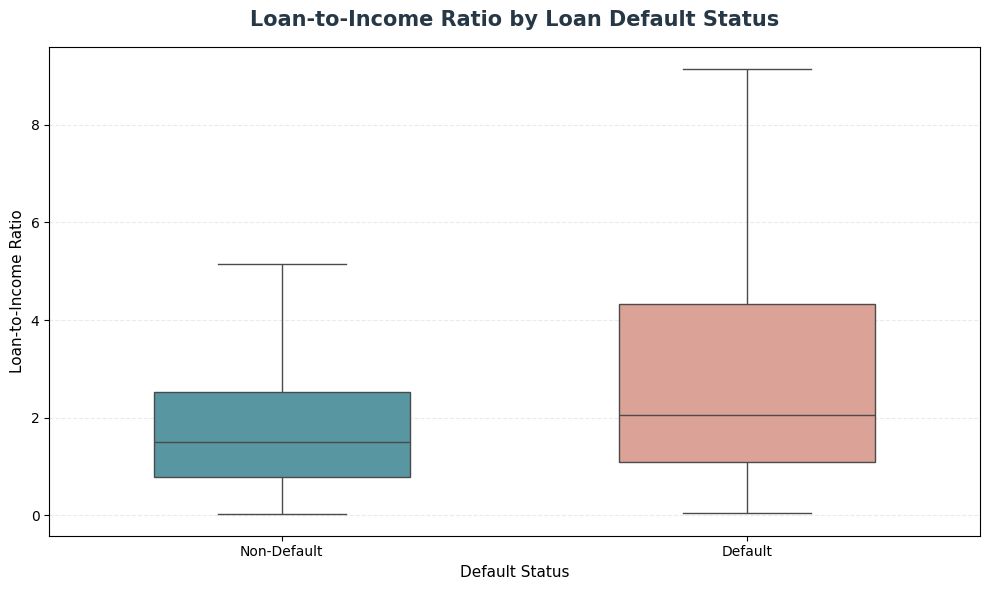

AVERAGE LOAN-TO-INCOME RATIO
Non-Default: 2.0362
Default: 3.2530

Difference between group averages: 1.2168


In [29]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Default',
    y='LoanToIncomeRatio',
    hue='Default',
    palette={0: '#4C9FAD', 1: '#E69A8D'},
    legend=False,
    showfliers=False,
    width=0.55
)

plt.title(
    'Loan-to-Income Ratio by Loan Default Status',
    fontsize=15,
    fontweight='bold',
    color='#263746',
    pad=15
)

plt.xlabel('Default Status', fontsize=11)
plt.ylabel('Loan-to-Income Ratio', fontsize=11)
plt.xticks([0, 1], ['Non-Default', 'Default'])
plt.grid(axis='y', linestyle='--', alpha=0.25)
plt.tight_layout()
plt.show()

print('AVERAGE LOAN-TO-INCOME RATIO')
print('=' * 50)

for status, group in df.groupby('Default'):
    label = 'Default' if status == 1 else 'Non-Default'
    print(f'{label}: {group["LoanToIncomeRatio"].mean():.4f}')

difference = (
    df.loc[df['Default'] == 1, 'LoanToIncomeRatio'].mean()
    - df.loc[df['Default'] == 0, 'LoanToIncomeRatio'].mean()
)

print(f'\nDifference between group averages: {difference:.4f}')

Update numerical features

In [30]:
numerical_features = [
    'Age',
    'Income',
    'LoanAmount',
    'CreditScore',
    'MonthsEmployed',
    'NumCreditLines',
    'InterestRate',
    'LoanTerm',
    'DTIRatio',
    'LoanToIncomeRatio'
]

categorical_features = [
    'Education',
    'EmploymentType',
    'MaritalStatus',
    'HasMortgage',
    'HasDependents',
    'LoanPurpose',
    'HasCoSigner'
]

target = 'Default'

print('UPDATED FEATURE CONFIGURATION')
print('=' * 55)
print('Numerical features:', len(numerical_features))
print('Categorical features:', len(categorical_features))
print('Total predictor features:', len(numerical_features) + len(categorical_features))
print('Target variable:', target)

display(pd.DataFrame({
    'Feature': numerical_features + categorical_features,
    'Feature Type': ['Numerical'] * len(numerical_features) +
                    ['Categorical'] * len(categorical_features)
}))

UPDATED FEATURE CONFIGURATION
Numerical features: 10
Categorical features: 7
Total predictor features: 17
Target variable: Default


,Feature,Feature Type
0,Age,Numerical
1,Income,Numerical
2,LoanAmount,Numerical
3,CreditScore,Numerical
4,MonthsEmployed,Numerical
5,NumCreditLines,Numerical
6,InterestRate,Numerical
7,LoanTerm,Numerical
8,DTIRatio,Numerical
9,LoanToIncomeRatio,Numerical


## **Define Features and Target**

**Stratified Train-Test Split**

In [31]:
from sklearn.model_selection import train_test_split

X = df[numerical_features + categorical_features].copy()
y = df['Default'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('TRAIN-TEST SPLIT RESULTS')
print('=' * 60)

print(f'Total dataset:       {len(df):,}')
print(f'Training samples:    {len(X_train):,}')
print(f'Testing samples:     {len(X_test):,}')
print(f'Number of features:  {X_train.shape[1]}')

print('\nTRAINING TARGET DISTRIBUTION')
print('=' * 60)

train_distribution = pd.DataFrame({
    'Count': y_train.value_counts().sort_index(),
    'Percentage': y_train.value_counts(normalize=True).sort_index() * 100
})

train_distribution.index = ['Non-Default (0)', 'Default (1)']
display(train_distribution.style.format({
    'Count': '{:,.0f}',
    'Percentage': '{:.2f}%'
}))

print('\nTESTING TARGET DISTRIBUTION')
print('=' * 60)

test_distribution = pd.DataFrame({
    'Count': y_test.value_counts().sort_index(),
    'Percentage': y_test.value_counts(normalize=True).sort_index() * 100
})

test_distribution.index = ['Non-Default (0)', 'Default (1)']
display(test_distribution.style.format({
    'Count': '{:,.0f}',
    'Percentage': '{:.2f}%'
}))

print('\nSPLIT VALIDATION')
print('=' * 60)
print('Training and testing indices overlap:',
      len(set(X_train.index).intersection(set(X_test.index))) > 0)

print('Training feature shape:', X_train.shape)
print('Testing feature shape:', X_test.shape)

print('\nOriginal default rate:', f'{y.mean() * 100:.2f}%')
print('Training default rate:', f'{y_train.mean() * 100:.2f}%')
print('Testing default rate:', f'{y_test.mean() * 100:.2f}%')

TRAIN-TEST SPLIT RESULTS
Total dataset:       255,347
Training samples:    204,277
Testing samples:     51,070
Number of features:  17

TRAINING TARGET DISTRIBUTION


,Count,Percentage
Non-Default (0),"180,555",88.39%
Default (1),"23,722",11.61%



TESTING TARGET DISTRIBUTION


,Count,Percentage
Non-Default (0),"45,139",88.39%
Default (1),"5,931",11.61%



SPLIT VALIDATION
Training and testing indices overlap: False
Training feature shape: (204277, 17)
Testing feature shape: (51070, 17)

Original default rate: 11.61%
Training default rate: 11.61%
Testing default rate: 11.61%


## **Data Preprocessing – StandardScaler and OneHotEncoder**

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print('DATA PREPROCESSING RESULTS')
print('=' * 60)

print('Original training shape:', X_train.shape)
print('Original testing shape:', X_test.shape)

print('\nProcessed training shape:', X_train_processed.shape)
print('Processed testing shape:', X_test_processed.shape)

print('\nPREPROCESSING VALIDATION')
print('=' * 60)

print('Training samples:', X_train_processed.shape[0])
print('Testing samples:', X_test_processed.shape[0])
print('Processed features:', X_train_processed.shape[1])

print('\nMissing values in training:',
      np.isnan(X_train_processed).sum())

print('Missing values in testing:',
      np.isnan(X_test_processed).sum())

print('\nInfinite values in training:',
      np.isinf(X_train_processed).sum())

print('Infinite values in testing:',
      np.isinf(X_test_processed).sum())

print('\nPreprocessing fitted on training data only.')

DATA PREPROCESSING RESULTS
Original training shape: (204277, 17)
Original testing shape: (51070, 17)

Processed training shape: (204277, 32)
Processed testing shape: (51070, 32)

PREPROCESSING VALIDATION
Training samples: 204277
Testing samples: 51070
Processed features: 32

Missing values in training: 0
Missing values in testing: 0

Infinite values in training: 0
Infinite values in testing: 0

Preprocessing fitted on training data only.


# **Train normal machine learning algorithms**


LOGISTIC REGRESSION

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-Default       0.89      0.99      0.94     45139
     Default       0.61      0.07      0.13      5931

    accuracy                           0.89     51070
   macro avg       0.75      0.53      0.53     51070
weighted avg       0.86      0.89      0.84     51070

CONFUSION MATRIX
[[44880   259]
 [ 5518   413]]


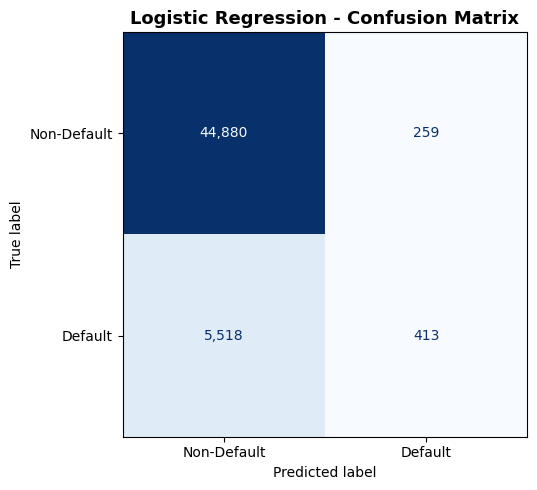


DECISION TREE

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-Default       0.90      0.88      0.89     45139
     Default       0.20      0.23      0.21      5931

    accuracy                           0.80     51070
   macro avg       0.55      0.55      0.55     51070
weighted avg       0.82      0.80      0.81     51070

CONFUSION MATRIX
[[39567  5572]
 [ 4556  1375]]


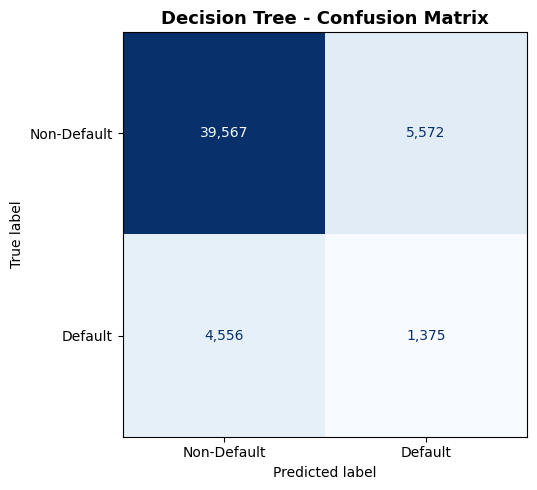


RANDOM FOREST

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-Default       0.89      1.00      0.94     45139
     Default       0.62      0.04      0.08      5931

    accuracy                           0.89     51070
   macro avg       0.76      0.52      0.51     51070
weighted avg       0.86      0.89      0.84     51070

CONFUSION MATRIX
[[44988   151]
 [ 5680   251]]


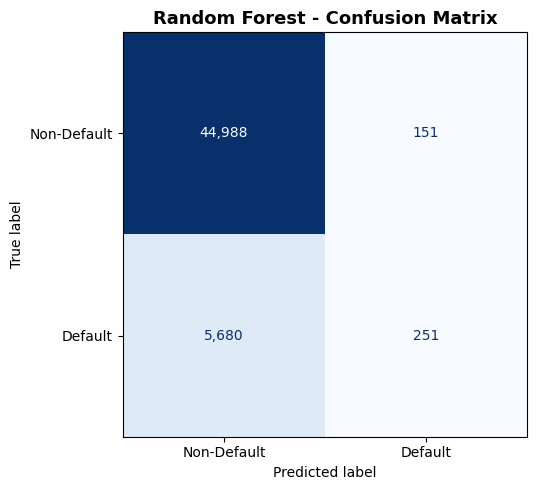


BASELINE MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8869,0.6146,0.0696,0.1251,0.7617,0.3365
1,Decision Tree,0.8017,0.1979,0.2318,0.2135,0.5542,0.1351
2,Random Forest,0.8858,0.6244,0.0423,0.0793,0.7423,0.3108


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

baseline_results = []
baseline_predictions = {}

for name, model in models.items():

    print('\n' + '=' * 70)
    print(name.upper())
    print('=' * 70)

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    baseline_predictions[name] = {
        'model': model,
        'predictions': y_pred,
        'probabilities': y_prob
    }

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    baseline_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc
    })

    print('\nCLASSIFICATION REPORT')
    print(classification_report(
        y_test,
        y_pred,
        target_names=['Non-Default', 'Default'],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred)

    print('CONFUSION MATRIX')
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Non-Default', 'Default']
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    disp.plot(
        cmap='Blues',
        values_format=',d',
        ax=ax,
        colorbar=False
    )

    plt.title(
        f'{name} - Confusion Matrix',
        fontsize=13,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()

baseline_comparison = pd.DataFrame(baseline_results)

print('\n' + '=' * 90)
print('BASELINE MODEL PERFORMANCE COMPARISON')
print('=' * 90)

display(
    baseline_comparison.style
    .format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
    .background_gradient(
        subset=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC'],
        cmap='YlGnBu'
    )
)

**XGBoost and LightGBM**


XGBOOST

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-Default       0.89      0.99      0.94     45139
     Default       0.60      0.07      0.13      5931

    accuracy                           0.89     51070
   macro avg       0.75      0.53      0.53     51070
weighted avg       0.86      0.89      0.85     51070

CONFUSION MATRIX
[[44852   287]
 [ 5498   433]]


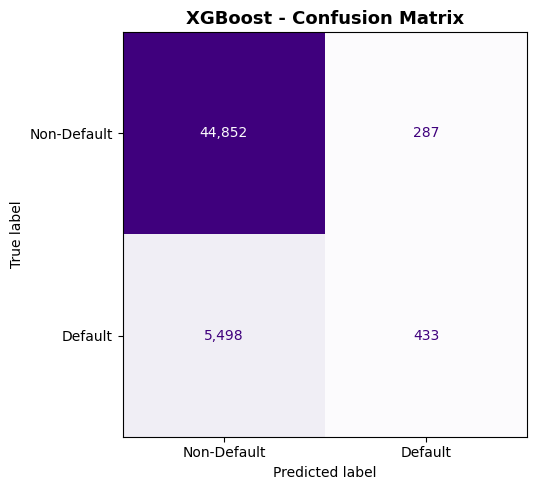


LIGHTGBM

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-Default       0.89      0.99      0.94     45139
     Default       0.61      0.07      0.13      5931

    accuracy                           0.89     51070
   macro avg       0.75      0.53      0.53     51070
weighted avg       0.86      0.89      0.85     51070

CONFUSION MATRIX
[[44862   277]
 [ 5499   432]]


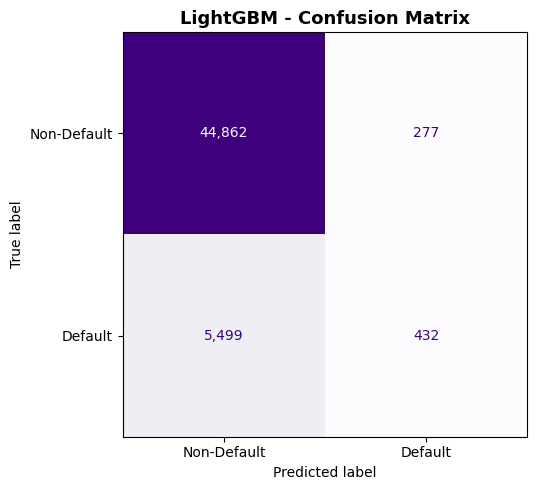


BOOSTING MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,XGBoost,0.8867,0.6014,0.0730,0.1302,0.7543,0.3237
1,LightGBM,0.8869,0.6093,0.0728,0.1301,0.7562,0.3278


In [34]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

boosting_models = {
    'XGBoost': XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ),

    'LightGBM': LGBMClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

boosting_results = []
boosting_predictions = {}

for name, model in boosting_models.items():

    print('\n' + '=' * 70)
    print(name.upper())
    print('=' * 70)

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    boosting_predictions[name] = {
        'model': model,
        'predictions': y_pred,
        'probabilities': y_prob
    }

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    boosting_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc
    })

    print('\nCLASSIFICATION REPORT')

    print(classification_report(
        y_test,
        y_pred,
        target_names=['Non-Default', 'Default'],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred)

    print('CONFUSION MATRIX')
    print(cm)

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Non-Default', 'Default']
    ).plot(
        cmap='Purples',
        values_format=',d',
        ax=ax,
        colorbar=False
    )

    plt.title(
        f'{name} - Confusion Matrix',
        fontsize=13,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()

boosting_comparison = pd.DataFrame(boosting_results)

print('\nBOOSTING MODEL PERFORMANCE COMPARISON')
print('=' * 90)

display(
    boosting_comparison.style
    .format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
    .background_gradient(
        subset=[
            'Accuracy', 'Precision', 'Recall',
            'F1-Score', 'ROC-AUC', 'PR-AUC'
        ],
        cmap='YlGnBu'
    )
)

**Five-Model Baseline Comparison**

COMPLETE BASELINE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8869,0.6146,0.0696,0.1251,0.7617,0.3365
1,LightGBM,0.8869,0.6093,0.0728,0.1301,0.7562,0.3278
2,XGBoost,0.8867,0.6014,0.0730,0.1302,0.7543,0.3237
3,Random Forest,0.8858,0.6244,0.0423,0.0793,0.7423,0.3108
4,Decision Tree,0.8017,0.1979,0.2318,0.2135,0.5542,0.1351


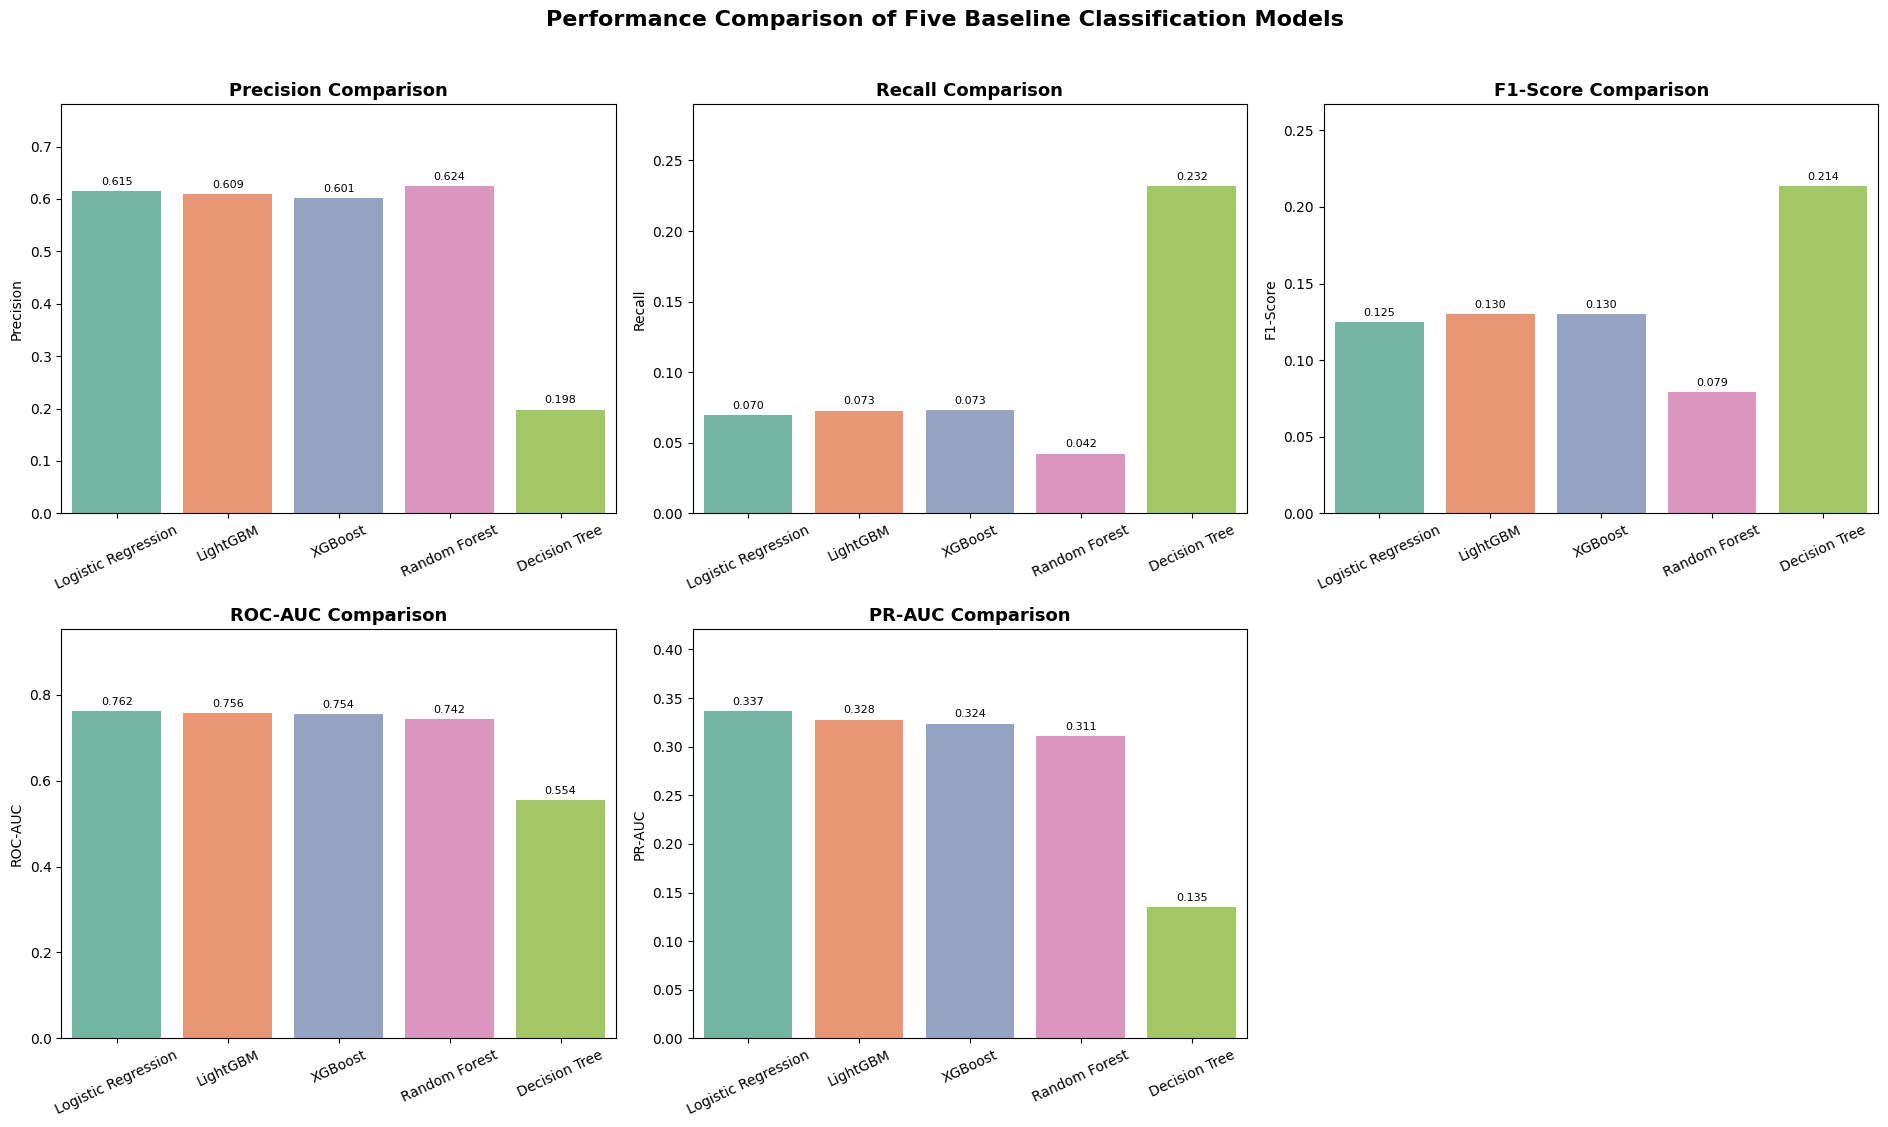

In [35]:
all_baseline_results = pd.concat(
    [baseline_comparison, boosting_comparison],
    ignore_index=True
)

all_baseline_results = all_baseline_results.sort_values(
    'PR-AUC',
    ascending=False
).reset_index(drop=True)

print('COMPLETE BASELINE MODEL COMPARISON')
print('=' * 90)

display(
    all_baseline_results.style
    .format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
    .background_gradient(
        subset=[
            'Precision', 'Recall', 'F1-Score',
            'ROC-AUC', 'PR-AUC'
        ],
        cmap='YlGnBu'
    )
)

metrics_to_plot = ['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']

fig, axes = plt.subplots(2, 3, figsize=(19, 11))
axes = axes.flatten()

colours = sns.color_palette('Set2', 5)

for i, metric in enumerate(metrics_to_plot):
    sns.barplot(
        data=all_baseline_results,
        x='Model',
        y=metric,
        hue='Model',
        palette=colours,
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f'{metric} Comparison',
        fontsize=13,
        fontweight='bold'
    )

    axes[i].set_xlabel('')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=25)
    axes[i].set_ylim(0, min(1, all_baseline_results[metric].max() * 1.25))

    for container in axes[i].containers:
        axes[i].bar_label(
            container,
            fmt='%.3f',
            padding=3,
            fontsize=8
        )

axes[5].axis('off')

plt.suptitle(
    'Performance Comparison of Five Baseline Classification Models',
    fontsize=16,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.show()

## **Handle class imbalance using class weighting**

Train five class-weighted models

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import numpy as np

class_ratio = (y_train == 0).sum() / (y_train == 1).sum()

weighted_models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        scale_pos_weight=class_ratio,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

weighted_results = []
weighted_predictions = {}

for name, model in weighted_models.items():

    print(f"\n{'='*70}")
    print(f"TRAINING: {name}")
    print(f"{'='*70}")

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    weighted_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })

    weighted_predictions[name] = {
        "model": model,
        "predictions": y_pred,
        "probabilities": y_prob
    }

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print(f"PR-AUC:    {pr_auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Non-Default", "Default"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

weighted_comparison = pd.DataFrame(weighted_results)

print("\nCLASS-WEIGHTED MODEL COMPARISON")
display(
    weighted_comparison
    .sort_values(by="F1-Score", ascending=False)
    .round(4)
)


TRAINING: Logistic Regression
Accuracy:  0.6909
Precision: 0.2281
Recall:    0.6968
F1-Score:  0.3437
ROC-AUC:   0.7616
PR-AUC:    0.3362

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.95      0.69      0.80     45139
     Default       0.23      0.70      0.34      5931

    accuracy                           0.69     51070
   macro avg       0.59      0.69      0.57     51070
weighted avg       0.86      0.69      0.75     51070

Confusion Matrix:
[[31152 13987]
 [ 1798  4133]]

TRAINING: Decision Tree
Accuracy:  0.8148
Precision: 0.1957
Recall:    0.1912
F1-Score:  0.1934
ROC-AUC:   0.5440
PR-AUC:    0.1313

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.89      0.90      0.90     45139
     Default       0.20      0.19      0.19      5931

    accuracy                           0.81     51070
   macro avg       0.54      0.54      0.54     51070
weighted avg       0.81      0.8

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
3,XGBoost,0.7036,0.2322,0.6726,0.3452,0.7578,0.3302
4,LightGBM,0.6972,0.2298,0.6832,0.3439,0.7589,0.3318
0,Logistic Regression,0.6909,0.2281,0.6968,0.3437,0.7616,0.3362
1,Decision Tree,0.8148,0.1957,0.1912,0.1934,0.5440,0.1313
2,Random Forest,0.8853,0.6697,0.0246,0.0475,0.7442,0.3100


**Compare baseline and class-weighted models**

In [37]:
baseline_comparison = pd.DataFrame(baseline_results)
weighted_comparison = pd.DataFrame(weighted_results)

baseline_comparison["Training Approach"] = "Baseline"
weighted_comparison["Training Approach"] = "Class-Weighted"

complete_comparison = pd.concat(
    [baseline_comparison, weighted_comparison],
    ignore_index=True
)

complete_comparison["Training Approach"] = pd.Categorical(
    complete_comparison["Training Approach"],
    categories=["Baseline", "Class-Weighted"],
    ordered=True
)

complete_comparison = complete_comparison.sort_values(
    by=["Model", "Training Approach"]
).reset_index(drop=True)

complete_comparison.insert(
    0,
    "No.",
    range(1, len(complete_comparison) + 1)
)

display(complete_comparison.round(4))

,No.,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Training Approach
0,1,Decision Tree,0.8017,0.1979,0.2318,0.2135,0.5542,0.1351,Baseline
1,2,Decision Tree,0.8148,0.1957,0.1912,0.1934,0.5440,0.1313,Class-Weighted
2,3,LightGBM,0.6972,0.2298,0.6832,0.3439,0.7589,0.3318,Class-Weighted
3,4,Logistic Regression,0.8869,0.6146,0.0696,0.1251,0.7617,0.3365,Baseline
4,5,Logistic Regression,0.6909,0.2281,0.6968,0.3437,0.7616,0.3362,Class-Weighted
5,6,Random Forest,0.8858,0.6244,0.0423,0.0793,0.7423,0.3108,Baseline
6,7,Random Forest,0.8853,0.6697,0.0246,0.0475,0.7442,0.3100,Class-Weighted
7,8,XGBoost,0.7036,0.2322,0.6726,0.3452,0.7578,0.3302,Class-Weighted


## ***Decision-threshold optimisation***

In [38]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Sub-training shape:", X_subtrain.shape)
print("Validation shape:", X_val.shape)

print("\nSub-training target distribution:")
print(y_subtrain.value_counts(normalize=True).round(4))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(4))

Sub-training shape: (163421, 32)
Validation shape: (40856, 32)

Sub-training target distribution:
Default
0    0.8839
1    0.1161
Name: proportion, dtype: float64

Validation target distribution:
Default
0    0.8839
1    0.1161
Name: proportion, dtype: float64


In [39]:
from sklearn.base import clone

threshold_models = {
    "Logistic Regression": clone(weighted_models["Logistic Regression"]),
    "XGBoost": clone(weighted_models["XGBoost"]),
    "LightGBM": clone(weighted_models["LightGBM"])
}

threshold_predictions = {}

for name, model in threshold_models.items():

    print(f"\nTraining {name}")

    model.fit(X_subtrain, y_subtrain)

    val_probabilities = model.predict_proba(X_val)[:, 1]

    threshold_predictions[name] = {
        "model": model,
        "probabilities": val_probabilities
    }

    print("Validation probabilities generated successfully.")


Training Logistic Regression
Validation probabilities generated successfully.

Training XGBoost
Validation probabilities generated successfully.

Training LightGBM
Validation probabilities generated successfully.


In [40]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_values = np.arange(0.05, 0.96, 0.01)

threshold_results = []
threshold_details = {}

for name, results in threshold_predictions.items():

    y_prob = results["probabilities"]

    model_threshold_results = []

    for threshold in threshold_values:

        y_pred = (y_prob >= threshold).astype(int)

        precision = precision_score(
            y_val, y_pred, zero_division=0
        )

        recall = recall_score(
            y_val, y_pred, zero_division=0
        )

        f1 = f1_score(
            y_val, y_pred, zero_division=0
        )

        model_threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1
        })

    model_df = pd.DataFrame(model_threshold_results)

    best_row = model_df.loc[model_df["F1-Score"].idxmax()]

    threshold_results.append(best_row.to_dict())

    threshold_details[name] = model_df

    print(f"\n{name}")
    print(f"Best Threshold: {best_row['Threshold']:.2f}")
    print(f"Precision: {best_row['Precision']:.4f}")
    print(f"Recall: {best_row['Recall']:.4f}")
    print(f"F1-Score: {best_row['F1-Score']:.4f}")

best_threshold_comparison = pd.DataFrame(threshold_results)

print("\nBEST VALIDATION THRESHOLD COMPARISON")
display(
    best_threshold_comparison
    .sort_values("F1-Score", ascending=False)
    .round(4)
)


Logistic Regression
Best Threshold: 0.63
Precision: 0.2996
Recall: 0.4774
F1-Score: 0.3682

XGBoost
Best Threshold: 0.62
Precision: 0.2922
Recall: 0.4623
F1-Score: 0.3580

LightGBM
Best Threshold: 0.63
Precision: 0.2980
Recall: 0.4640
F1-Score: 0.3629

BEST VALIDATION THRESHOLD COMPARISON


,Model,Threshold,Precision,Recall,F1-Score
0,Logistic Regression,0.63,0.2996,0.4774,0.3682
2,LightGBM,0.63,0.2980,0.4640,0.3629
1,XGBoost,0.62,0.2922,0.4623,0.3580


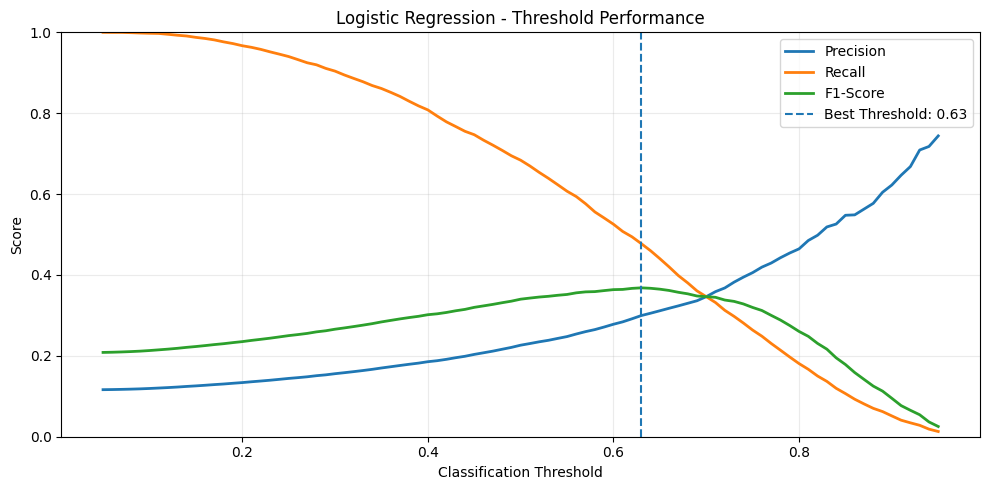

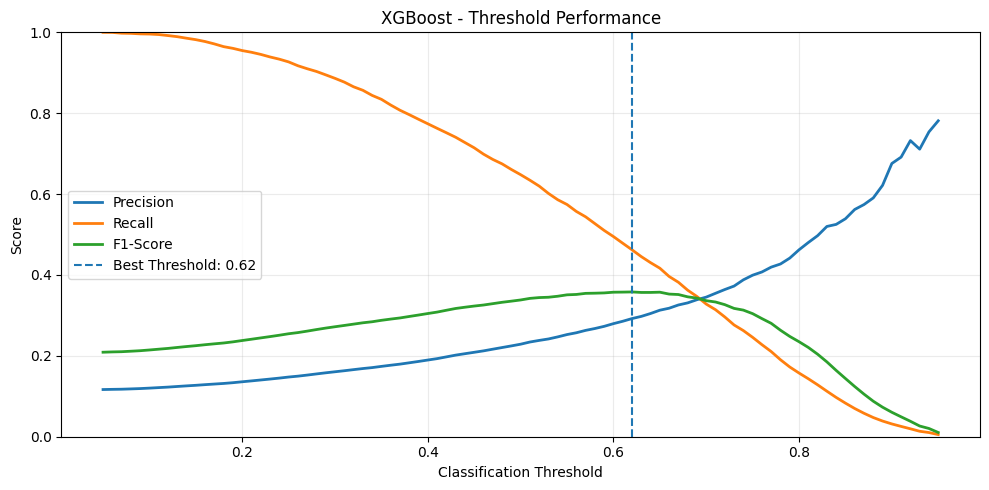

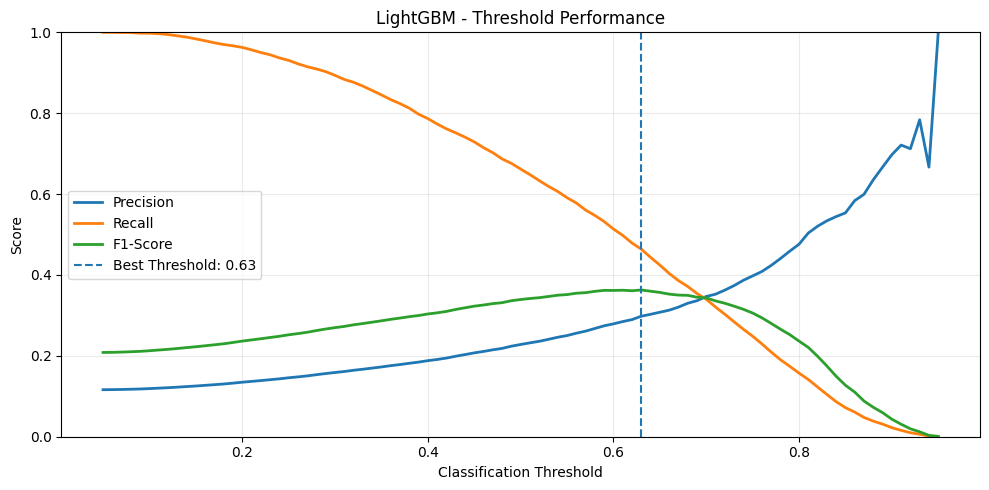

In [41]:
import matplotlib.pyplot as plt

for name, results in threshold_details.items():

    plt.figure(figsize=(10, 5))

    plt.plot(
        results["Threshold"],
        results["Precision"],
        label="Precision",
        linewidth=2
    )

    plt.plot(
        results["Threshold"],
        results["Recall"],
        label="Recall",
        linewidth=2
    )

    plt.plot(
        results["Threshold"],
        results["F1-Score"],
        label="F1-Score",
        linewidth=2
    )

    best_threshold = best_threshold_comparison.loc[
        best_threshold_comparison["Model"] == name,
        "Threshold"
    ].iloc[0]

    plt.axvline(
        best_threshold,
        linestyle="--",
        label=f"Best Threshold: {best_threshold:.2f}"
    )

    plt.title(f"{name} - Threshold Performance")
    plt.xlabel("Classification Threshold")
    plt.ylabel("Score")
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

In [42]:
from sklearn.metrics import confusion_matrix, classification_report

for _, row in best_threshold_comparison.iterrows():

    name = row["Model"]
    threshold = row["Threshold"]

    y_prob = threshold_predictions[name]["probabilities"]
    y_pred = (y_prob >= threshold).astype(int)

    print(f"\n{'='*60}")
    print(f"{name} - Optimised Validation Threshold: {threshold:.2f}")
    print(f"{'='*60}")

    print("\nClassification Report:")
    print(classification_report(
        y_val,
        y_pred,
        target_names=["Non-Default", "Default"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_val, y_pred))


Logistic Regression - Optimised Validation Threshold: 0.63

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.93      0.85      0.89     36112
     Default       0.30      0.48      0.37      4744

    accuracy                           0.81     40856
   macro avg       0.61      0.67      0.63     40856
weighted avg       0.85      0.81      0.83     40856

Confusion Matrix:
[[30817  5295]
 [ 2479  2265]]

XGBoost - Optimised Validation Threshold: 0.62

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.92      0.85      0.89     36112
     Default       0.29      0.46      0.36      4744

    accuracy                           0.81     40856
   macro avg       0.61      0.66      0.62     40856
weighted avg       0.85      0.81      0.83     40856

Confusion Matrix:
[[30799  5313]
 [ 2551  2193]]

LightGBM - Optimised Validation Threshold: 0.63

Classification Report:
              preci

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_subtrain_raw, X_val_raw, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

validation_preprocessor = clone(preprocessor)

X_subtrain = validation_preprocessor.fit_transform(X_subtrain_raw)
X_val = validation_preprocessor.transform(X_val_raw)

print("Sub-training shape:", X_subtrain.shape)
print("Validation shape:", X_val.shape)

print("\nSub-training distribution:")
print(y_subtrain.value_counts(normalize=True).round(4))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True).round(4))

Sub-training shape: (163421, 32)
Validation shape: (40856, 32)

Sub-training distribution:
Default
0    0.8839
1    0.1161
Name: proportion, dtype: float64

Validation distribution:
Default
0    0.8839
1    0.1161
Name: proportion, dtype: float64


In [44]:
class_ratio = (y_subtrain == 0).sum() / (y_subtrain == 1).sum()

threshold_models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        scale_pos_weight=class_ratio,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

threshold_predictions = {}

for name, model in threshold_models.items():

    model.fit(X_subtrain, y_subtrain)

    val_probabilities = model.predict_proba(X_val)[:, 1]

    threshold_predictions[name] = {
        "model": model,
        "probabilities": val_probabilities
    }

    print(f"{name}: validation predictions generated.")

Logistic Regression: validation predictions generated.
XGBoost: validation predictions generated.
LightGBM: validation predictions generated.


Optimise classification thresholds

In [45]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_values = np.arange(0.05, 0.96, 0.01)

threshold_results = []
threshold_details = {}

for name, results in threshold_predictions.items():

    y_prob = results["probabilities"]

    model_threshold_results = []

    for threshold in threshold_values:

        y_pred = (y_prob >= threshold).astype(int)

        precision = precision_score(
            y_val, y_pred, zero_division=0
        )

        recall = recall_score(
            y_val, y_pred, zero_division=0
        )

        f1 = f1_score(
            y_val, y_pred, zero_division=0
        )

        model_threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1
        })

    model_df = pd.DataFrame(model_threshold_results)

    best_row = model_df.loc[
        model_df["F1-Score"].idxmax()
    ]

    threshold_results.append(best_row.to_dict())

    threshold_details[name] = model_df

    print(f"\n{name}")
    print(f"Best Threshold: {best_row['Threshold']:.2f}")
    print(f"Precision: {best_row['Precision']:.4f}")
    print(f"Recall: {best_row['Recall']:.4f}")
    print(f"F1-Score: {best_row['F1-Score']:.4f}")

best_threshold_comparison = pd.DataFrame(threshold_results)

best_threshold_comparison = best_threshold_comparison.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\nOPTIMISED VALIDATION THRESHOLD COMPARISON")

display(best_threshold_comparison.round(4))


Logistic Regression
Best Threshold: 0.63
Precision: 0.2996
Recall: 0.4774
F1-Score: 0.3681

XGBoost
Best Threshold: 0.62
Precision: 0.2922
Recall: 0.4623
F1-Score: 0.3580

LightGBM
Best Threshold: 0.62
Precision: 0.2921
Recall: 0.4817
F1-Score: 0.3636

OPTIMISED VALIDATION THRESHOLD COMPARISON


,Model,Threshold,Precision,Recall,F1-Score
0,Logistic Regression,0.63,0.2996,0.4774,0.3681
1,LightGBM,0.62,0.2921,0.4817,0.3636
2,XGBoost,0.62,0.2922,0.4623,0.3580


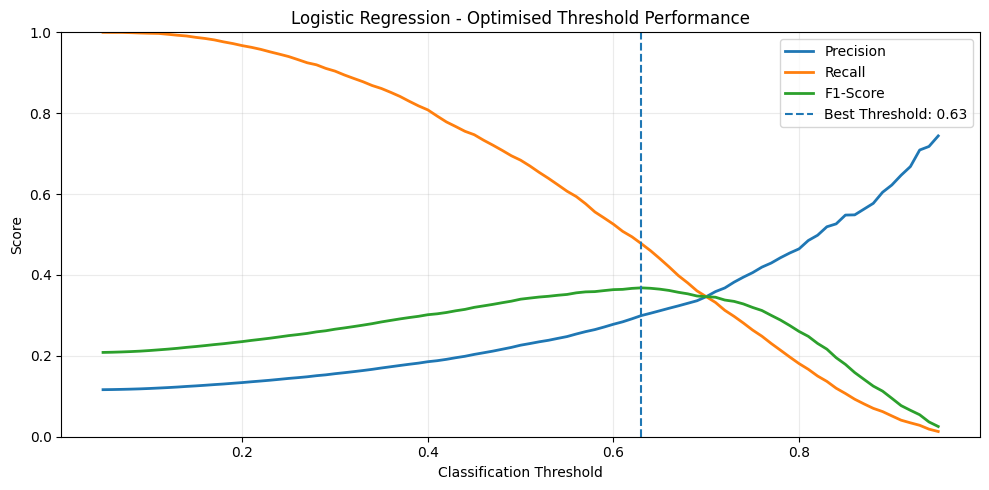

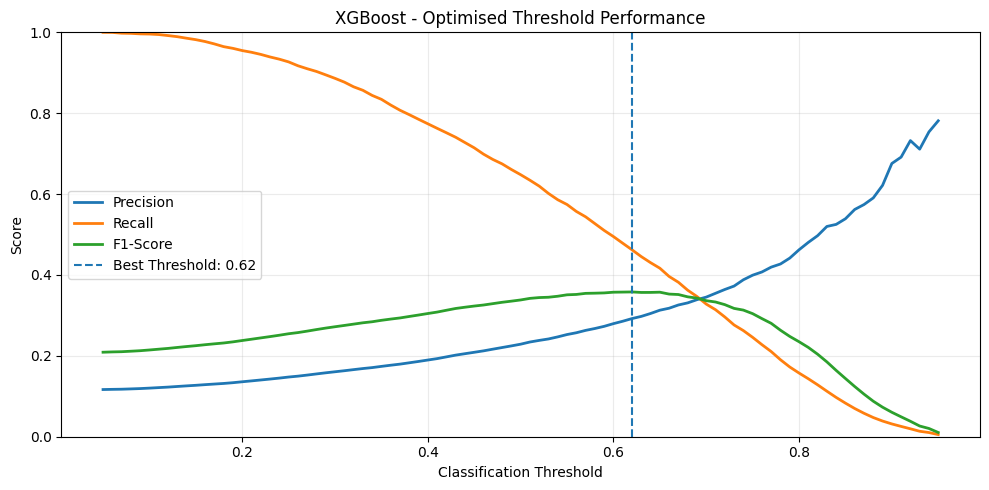

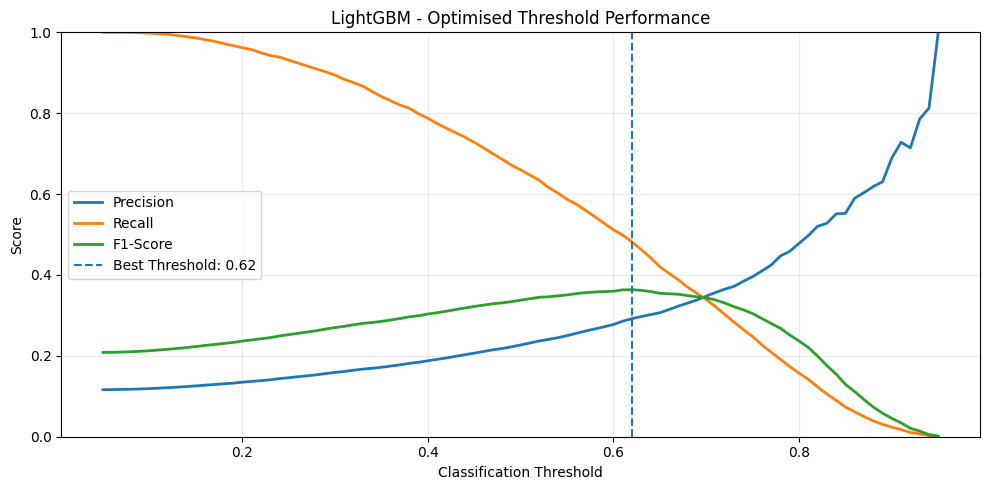

In [46]:
import matplotlib.pyplot as plt

for name, results in threshold_details.items():

    plt.figure(figsize=(10, 5))

    plt.plot(
        results["Threshold"],
        results["Precision"],
        label="Precision",
        linewidth=2
    )

    plt.plot(
        results["Threshold"],
        results["Recall"],
        label="Recall",
        linewidth=2
    )

    plt.plot(
        results["Threshold"],
        results["F1-Score"],
        label="F1-Score",
        linewidth=2
    )

    best_threshold = best_threshold_comparison.loc[
        best_threshold_comparison["Model"] == name,
        "Threshold"
    ].iloc[0]

    plt.axvline(
        best_threshold,
        linestyle="--",
        label=f"Best Threshold: {best_threshold:.2f}"
    )

    plt.title(f"{name} - Optimised Threshold Performance")
    plt.xlabel("Classification Threshold")
    plt.ylabel("Score")
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

In [47]:
from sklearn.metrics import confusion_matrix, classification_report

for _, row in best_threshold_comparison.iterrows():

    name = row["Model"]
    threshold = row["Threshold"]

    y_prob = threshold_predictions[name]["probabilities"]
    y_pred = (y_prob >= threshold).astype(int)

    print(f"\n{'='*60}")
    print(f"{name} | Threshold: {threshold:.2f}")
    print(f"{'='*60}")

    print("\nClassification Report:")

    print(classification_report(
        y_val,
        y_pred,
        target_names=["Non-Default", "Default"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_val, y_pred))


Logistic Regression | Threshold: 0.63

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.93      0.85      0.89     36112
     Default       0.30      0.48      0.37      4744

    accuracy                           0.81     40856
   macro avg       0.61      0.67      0.63     40856
weighted avg       0.85      0.81      0.83     40856

Confusion Matrix:
[[30816  5296]
 [ 2479  2265]]

LightGBM | Threshold: 0.62

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.93      0.85      0.88     36112
     Default       0.29      0.48      0.36      4744

    accuracy                           0.80     40856
   macro avg       0.61      0.66      0.62     40856
weighted avg       0.85      0.80      0.82     40856

Confusion Matrix:
[[30573  5539]
 [ 2459  2285]]

XGBoost | Threshold: 0.62

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.92    

## **Final model training using the complete training dataset**

In [48]:
from sklearn.linear_model import LogisticRegression

X_train_final = preprocessor.fit_transform(X_train)
X_test_final = preprocessor.transform(X_test)

final_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

final_model.fit(X_train_final, y_train)

print("Final Logistic Regression model trained successfully.")
print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

Final Logistic Regression model trained successfully.
Training shape: (204277, 32)
Testing shape: (51070, 32)


In [49]:
selected_threshold = 0.63

y_test_prob = final_model.predict_proba(X_test_final)[:, 1]

y_test_pred = (
    y_test_prob >= selected_threshold
).astype(int)

print("Selected threshold:", selected_threshold)
print("Test predictions generated successfully.")

Selected threshold: 0.63
Test predictions generated successfully.


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

final_accuracy = accuracy_score(y_test, y_test_pred)
final_precision = precision_score(y_test, y_test_pred, zero_division=0)
final_recall = recall_score(y_test, y_test_pred, zero_division=0)
final_f1 = f1_score(y_test, y_test_pred, zero_division=0)
final_roc_auc = roc_auc_score(y_test, y_test_prob)
final_pr_auc = average_precision_score(y_test, y_test_prob)

final_results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Training Approach": "Class-Weighted",
    "Threshold": selected_threshold,
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1-Score": final_f1,
    "ROC-AUC": final_roc_auc,
    "PR-AUC": final_pr_auc
}])

print("FINAL TEST PERFORMANCE")
display(final_results.round(4))

print("\nFINAL CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Non-Default", "Default"],
    zero_division=0
))

print("\nFINAL CONFUSION MATRIX")

final_cm = confusion_matrix(y_test, y_test_pred)

print(final_cm)

FINAL TEST PERFORMANCE


,Model,Training Approach,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,Class-Weighted,0.63,0.8099,0.3036,0.4922,0.3755,0.7616,0.3362



FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-Default       0.93      0.85      0.89     45139
     Default       0.30      0.49      0.38      5931

    accuracy                           0.81     51070
   macro avg       0.62      0.67      0.63     51070
weighted avg       0.85      0.81      0.83     51070


FINAL CONFUSION MATRIX
[[38442  6697]
 [ 3012  2919]]


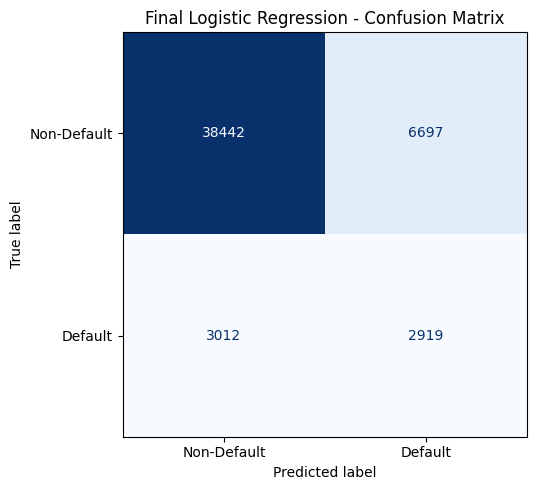

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Non-Default", "Default"]
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Final Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

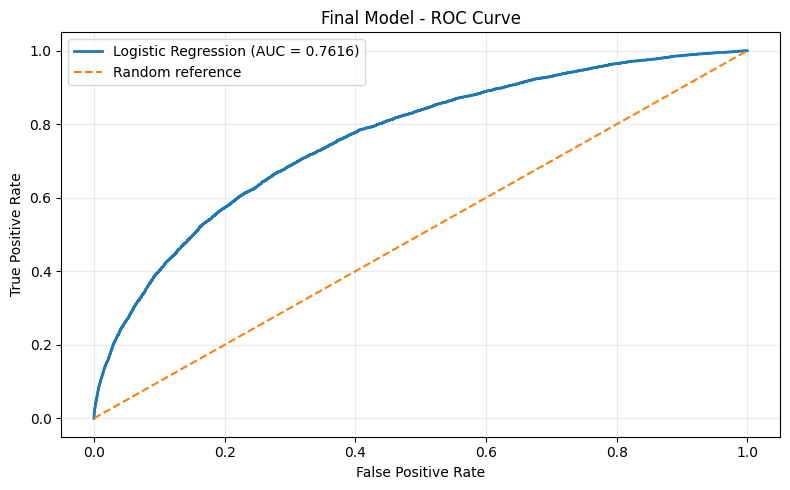

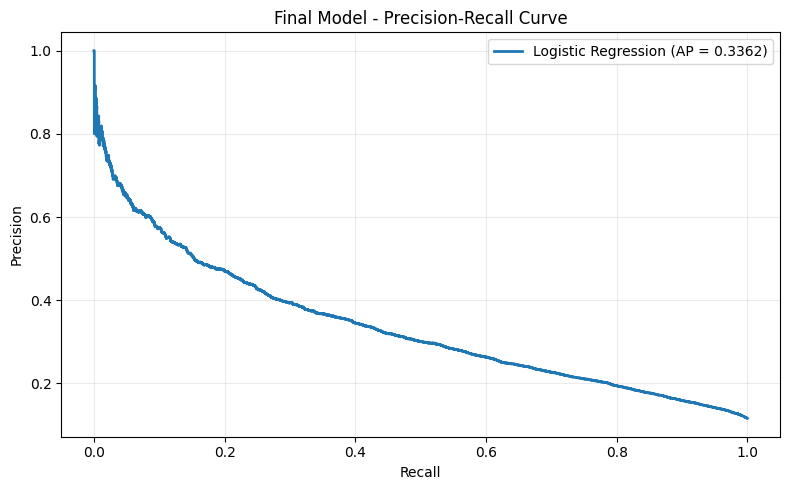

In [52]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
    average_precision_score
)

fpr, tpr, _ = roc_curve(y_test, y_test_prob)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {final_roc_auc:.4f})",
    linewidth=2
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random reference")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Model - ROC Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    y_test_prob
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Logistic Regression (AP = {final_pr_auc:.4f})",
    linewidth=2
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Model - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# **Explainable AI using SHAP**

In [53]:
!pip install shap -q

In [54]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [55]:
feature_names = preprocessor.get_feature_names_out()

X_train_dense = (
    X_train_final.toarray()
    if hasattr(X_train_final, "toarray")
    else np.asarray(X_train_final)
)

X_test_dense = (
    X_test_final.toarray()
    if hasattr(X_test_final, "toarray")
    else np.asarray(X_test_final)
)

rng = np.random.default_rng(42)

background_indices = rng.choice(
    len(X_train_dense),
    size=500,
    replace=False
)

explanation_indices = rng.choice(
    len(X_test_dense),
    size=1000,
    replace=False
)

X_background = pd.DataFrame(
    X_train_dense[background_indices],
    columns=feature_names
)

X_explain = pd.DataFrame(
    X_test_dense[explanation_indices],
    columns=feature_names
)

print("Background dataset:", X_background.shape)
print("Explanation dataset:", X_explain.shape)

Background dataset: (500, 32)
Explanation dataset: (1000, 32)


In [56]:
background_masker = shap.maskers.Independent(
    X_background,
    max_samples=500
)

explainer = shap.LinearExplainer(
    final_model,
    background_masker
)

shap_values = explainer(X_explain)

print("SHAP calculation completed.")
print("Background samples:", len(X_background))
print("Explained samples:", len(X_explain))
print("SHAP values shape:", shap_values.values.shape)

SHAP calculation completed.
Background samples: 500
Explained samples: 1000
SHAP values shape: (1000, 32)


In [57]:
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": np.abs(shap_values.values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)

print("TOP 15 FEATURES BASED ON SHAP IMPORTANCE")

display(shap_importance.head(15).round(4))

TOP 15 FEATURES BASED ON SHAP IMPORTANCE


,Feature,Mean Absolute SHAP
0,num__Age,0.5013
1,num__InterestRate,0.3941
2,num__LoanToIncomeRatio,0.3337
3,num__MonthsEmployed,0.2936
4,num__CreditScore,0.1108
5,cat__EmploymentType_Full-time,0.0961
6,num__NumCreditLines,0.0940
7,cat__HasCoSigner_Yes,0.0920
8,cat__HasDependents_Yes,0.0898
9,cat__MaritalStatus_Married,0.0683


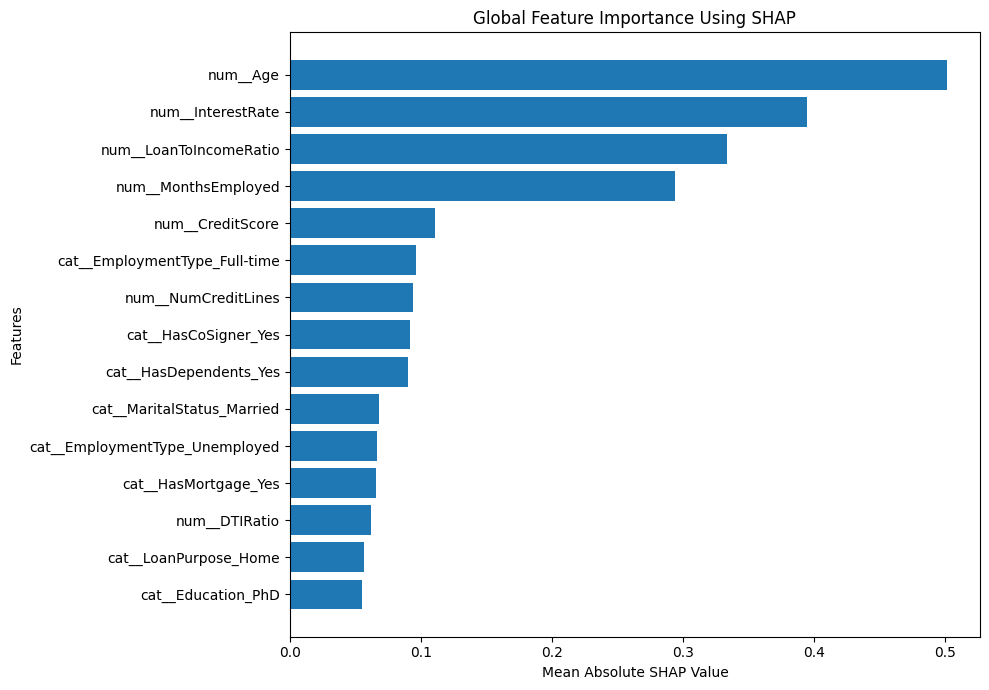

In [58]:
plt.figure(figsize=(10, 7))

top_features = shap_importance.head(15).sort_values(
    "Mean Absolute SHAP"
)

plt.barh(
    top_features["Feature"],
    top_features["Mean Absolute SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("Global Feature Importance Using SHAP")
plt.tight_layout()
plt.show()

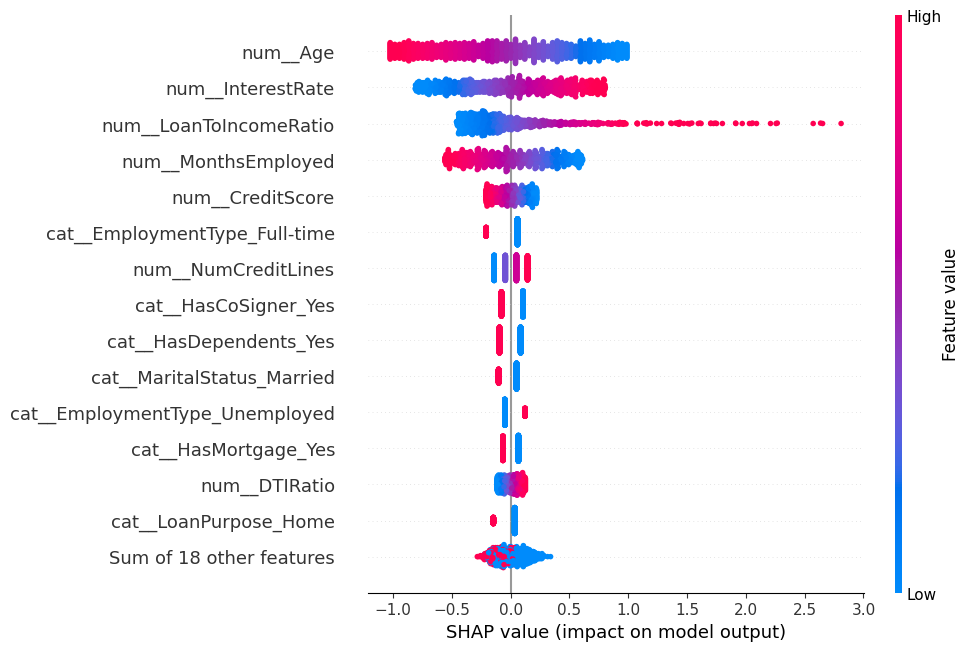

In [59]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

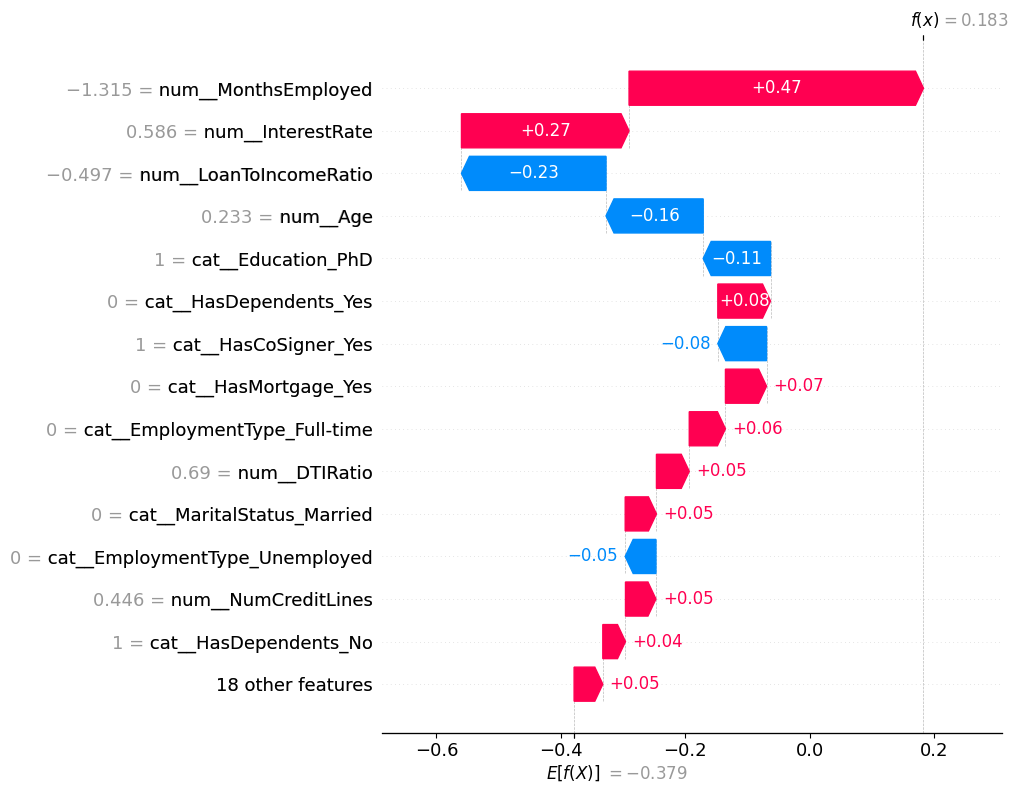

In [60]:
shap.plots.waterfall(
    shap_values[0],
    max_display=15
)

## **Model reliability and calibration**

In [61]:
from sklearn.metrics import brier_score_loss

brier_score = brier_score_loss(
    y_test,
    y_test_prob
)

print("MODEL CALIBRATION EVALUATION")
print("=" * 45)
print(f"Brier Score: {brier_score:.4f}")

MODEL CALIBRATION EVALUATION
Brier Score: 0.1997


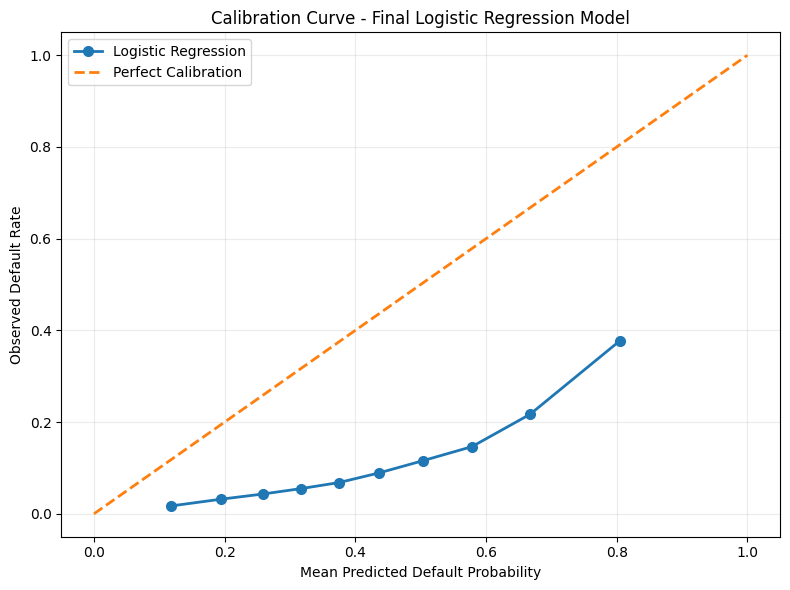

In [62]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    y_test_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    markersize=7,
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Rate")
plt.title("Calibration Curve - Final Logistic Regression Model")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

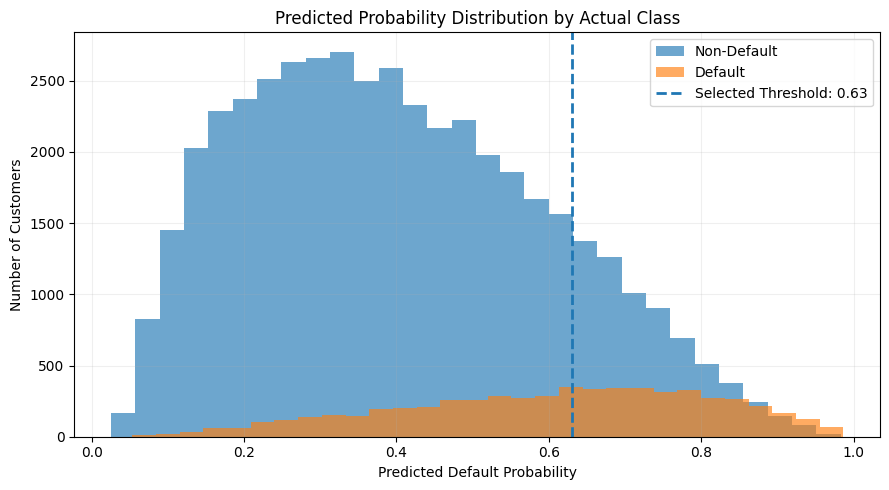

In [63]:
plt.figure(figsize=(9, 5))

plt.hist(
    y_test_prob[y_test == 0],
    bins=30,
    alpha=0.65,
    label="Non-Default"
)

plt.hist(
    y_test_prob[y_test == 1],
    bins=30,
    alpha=0.65,
    label="Default"
)

plt.axvline(
    selected_threshold,
    linestyle="--",
    linewidth=2,
    label=f"Selected Threshold: {selected_threshold:.2f}"
)

plt.xlabel("Predicted Default Probability")
plt.ylabel("Number of Customers")
plt.title("Predicted Probability Distribution by Actual Class")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [64]:
calibration_data = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Predicted_Probability": y_test_prob
})

calibration_data["Probability_Group"] = pd.qcut(
    calibration_data["Predicted_Probability"],
    q=10,
    duplicates="drop"
)

calibration_table = calibration_data.groupby(
    "Probability_Group",
    observed=True
).agg(
    Customers=("Actual", "count"),
    Mean_Predicted_Probability=("Predicted_Probability", "mean"),
    Observed_Default_Rate=("Actual", "mean")
).reset_index()

display(calibration_table.round(4))

,Probability_Group,Customers,Mean_Predicted_Probability,Observed_Default_Rate
0,"(0.024499999999999997, 0.161]",5107,0.1175,0.0170
1,"(0.161, 0.228]",5107,0.1949,0.0319
2,"(0.228, 0.288]",5107,0.2582,0.0431
3,"(0.288, 0.345]",5107,0.3165,0.0548
4,"(0.345, 0.405]",5107,0.3751,0.0681
5,"(0.405, 0.47]",5107,0.4367,0.0893
6,"(0.47, 0.539]",5107,0.5038,0.1159
7,"(0.539, 0.62]",5107,0.5786,0.1465
8,"(0.62, 0.721]",5107,0.6676,0.2172
9,"(0.721, 0.986]",5107,0.8051,0.3775


**Probability calibration using sigmoid calibration**

In [65]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_model = CalibratedClassifierCV(
    estimator=LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_subtrain, y_subtrain)

print("Calibrated Logistic Regression trained successfully.")

Calibrated Logistic Regression trained successfully.


In [66]:
y_val_calibrated_prob = calibrated_model.predict_proba(X_val)[:, 1]

print("Calibrated validation probabilities generated.")
print("Minimum probability:", round(y_val_calibrated_prob.min(), 4))
print("Maximum probability:", round(y_val_calibrated_prob.max(), 4))

Calibrated validation probabilities generated.
Minimum probability: 0.003
Maximum probability: 0.9253


In [67]:
from sklearn.metrics import brier_score_loss

original_brier = brier_score_loss(
    y_val,
    threshold_predictions["Logistic Regression"]["probabilities"]
)

calibrated_brier = brier_score_loss(
    y_val,
    y_val_calibrated_prob
)

reference_probability = y_val.mean()

reference_brier = brier_score_loss(
    y_val,
    np.full(len(y_val), reference_probability)
)

brier_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Calibrated Logistic Regression",
        "Prevalence Reference"
    ],
    "Brier Score": [
        original_brier,
        calibrated_brier,
        reference_brier
    ]
})

display(brier_comparison.round(4))

,Model,Brier Score
0,Original Logistic Regression,0.1997
1,Calibrated Logistic Regression,0.0912
2,Prevalence Reference,0.1026


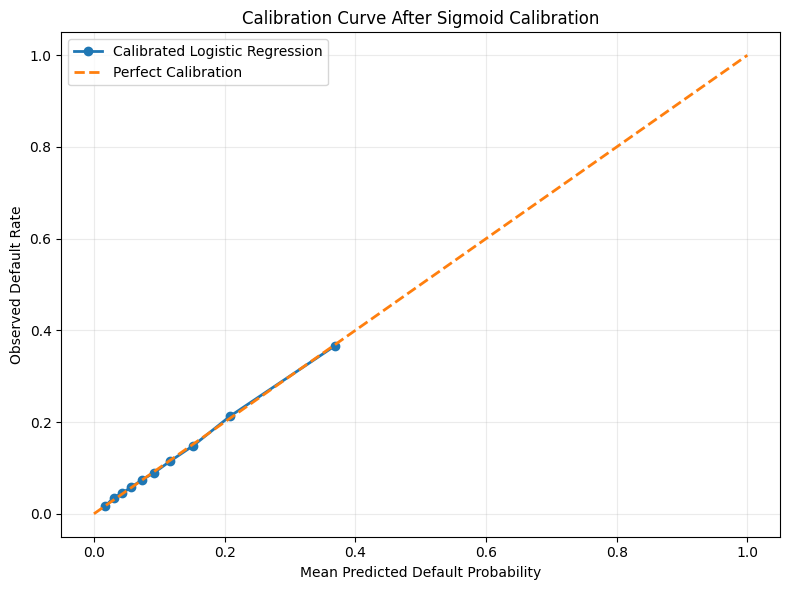

In [68]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

fraction_positive, mean_predicted = calibration_curve(
    y_val,
    y_val_calibrated_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    label="Calibrated Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Rate")
plt.title("Calibration Curve After Sigmoid Calibration")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [69]:
calibrated_threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.01):

    y_pred = (
        y_val_calibrated_prob >= threshold
    ).astype(int)

    calibrated_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_pred, zero_division=0
        )
    })

calibrated_threshold_table = pd.DataFrame(
    calibrated_threshold_results
)

best_calibrated_row = calibrated_threshold_table.loc[
    calibrated_threshold_table["F1-Score"].idxmax()
]

print("BEST CALIBRATED THRESHOLD")
display(best_calibrated_row.to_frame().round(4))

BEST CALIBRATED THRESHOLD


,13
Threshold,0.1800
Precision,0.2962
Recall,0.4844
F1-Score,0.3676


**Compare calibration performance**

In [70]:
from sklearn.metrics import brier_score_loss, log_loss

original_val_prob = threshold_predictions[
    "Logistic Regression"
]["probabilities"]

calibration_comparison = pd.DataFrame({
    "Metric": ["Brier Score", "Log Loss"],
    "Original Logistic Regression": [
        brier_score_loss(y_val, original_val_prob),
        log_loss(y_val, original_val_prob)
    ],
    "Calibrated Logistic Regression": [
        brier_score_loss(y_val, y_val_calibrated_prob),
        log_loss(y_val, y_val_calibrated_prob)
    ]
})

display(calibration_comparison.round(4))

,Metric,Original Logistic Regression,Calibrated Logistic Regression
0,Brier Score,0.1997,0.0912
1,Log Loss,0.5842,0.3129


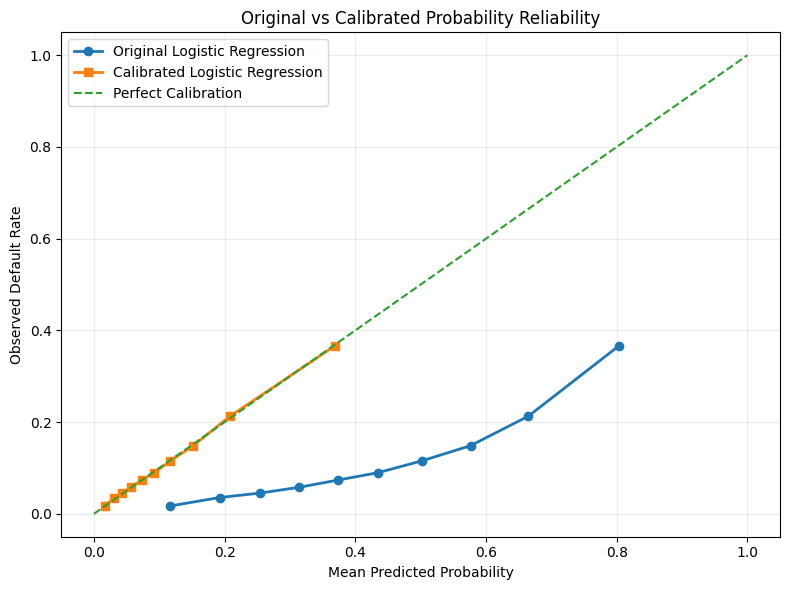

In [71]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

original_fraction, original_mean = calibration_curve(
    y_val,
    original_val_prob,
    n_bins=10,
    strategy="quantile"
)

calibrated_fraction, calibrated_mean = calibration_curve(
    y_val,
    y_val_calibrated_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    original_mean,
    original_fraction,
    marker="o",
    linewidth=2,
    label="Original Logistic Regression"
)

plt.plot(
    calibrated_mean,
    calibrated_fraction,
    marker="s",
    linewidth=2,
    label="Calibrated Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Default Rate")
plt.title("Original vs Calibrated Probability Reliability")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Train the final calibrated pipeline**

In [72]:
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

base_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

calibrated_final_model = CalibratedClassifierCV(
    estimator=base_pipeline,
    method="sigmoid",
    cv=5
)

calibrated_final_model.fit(X_train, y_train)

print("Final calibrated model trained successfully.")

Final calibrated model trained successfully.


In [73]:
calibrated_selected_threshold = 0.18

y_test_calibrated_prob = calibrated_final_model.predict_proba(
    X_test
)[:, 1]

y_test_calibrated_pred = (
    y_test_calibrated_prob >= calibrated_selected_threshold
).astype(int)

print("Test predictions generated successfully.")
print("Selected threshold:", calibrated_selected_threshold)

Test predictions generated successfully.
Selected threshold: 0.18


In [74]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    classification_report,
    confusion_matrix
)

calibrated_test_results = pd.DataFrame([{
    "Model": "Calibrated Logistic Regression",
    "Threshold": calibrated_selected_threshold,
    "Accuracy": accuracy_score(y_test, y_test_calibrated_pred),
    "Precision": precision_score(y_test, y_test_calibrated_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_calibrated_pred, zero_division=0),
    "F1-Score": f1_score(y_test, y_test_calibrated_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_calibrated_prob),
    "PR-AUC": average_precision_score(y_test, y_test_calibrated_prob),
    "Brier Score": brier_score_loss(y_test, y_test_calibrated_prob),
    "Log Loss": log_loss(y_test, y_test_calibrated_prob)
}])

print("FINAL CALIBRATED MODEL - TEST RESULTS")
display(calibrated_test_results.round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_calibrated_pred,
    target_names=["Non-Default", "Default"],
    zero_division=0
))

calibrated_cm = confusion_matrix(
    y_test,
    y_test_calibrated_pred
)

print("\nCONFUSION MATRIX")
print(calibrated_cm)

FINAL CALIBRATED MODEL - TEST RESULTS


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Calibrated Logistic Regression,0.18,0.8069,0.3009,0.5011,0.376,0.7616,0.3362,0.0903,0.3096



CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-Default       0.93      0.85      0.89     45139
     Default       0.30      0.50      0.38      5931

    accuracy                           0.81     51070
   macro avg       0.61      0.67      0.63     51070
weighted avg       0.86      0.81      0.83     51070


CONFUSION MATRIX
[[38234  6905]
 [ 2959  2972]]


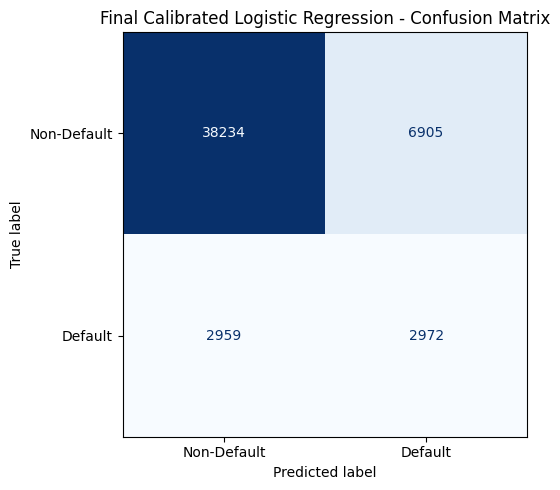

In [75]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=calibrated_cm,
    display_labels=["Non-Default", "Default"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Final Calibrated Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

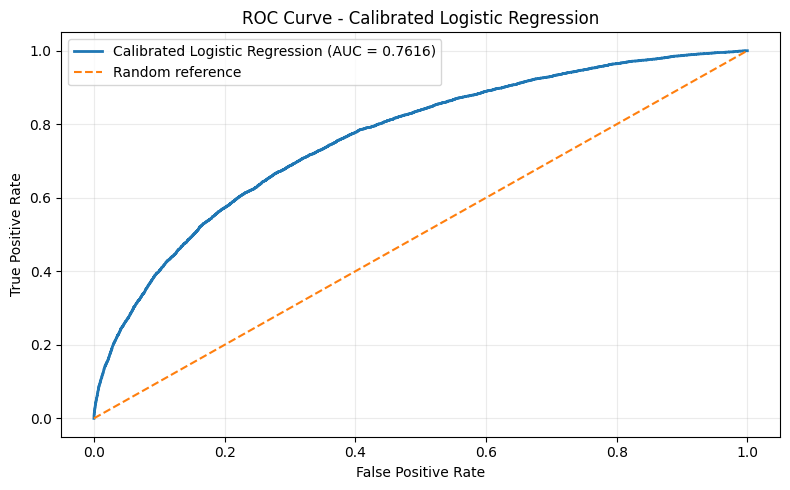

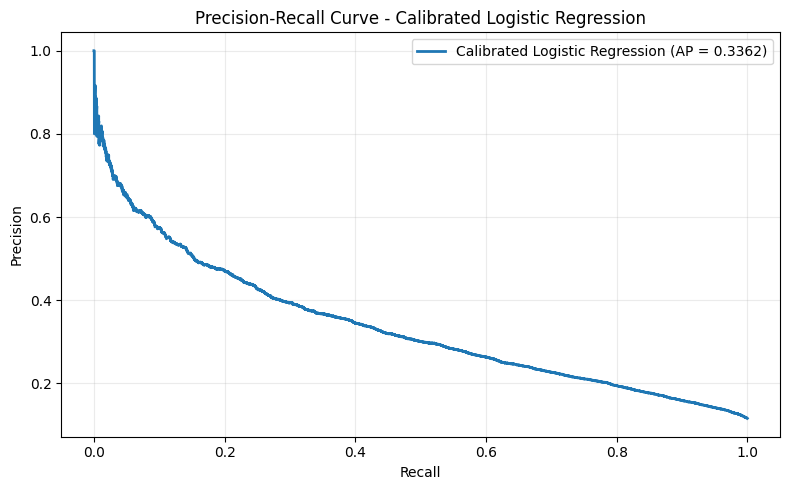

In [76]:
from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, _ = roc_curve(
    y_test,
    y_test_calibrated_prob
)

plt.figure(figsize=(8, 5))
plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Calibrated Logistic Regression (AUC = {roc_auc_score(y_test, y_test_calibrated_prob):.4f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random reference")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Calibrated Logistic Regression")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    y_test_calibrated_prob
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"Calibrated Logistic Regression (AP = {average_precision_score(y_test, y_test_calibrated_prob):.4f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Calibrated Logistic Regression")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Fairness and subgroup performance analysis**

In [77]:
X_test_groups = X_test.copy()

age_edges = np.unique(
    X_train["Age"].quantile([0, 0.25, 0.50, 0.75, 1]).values
)

X_test_groups["Age_Group"] = pd.cut(
    X_test_groups["Age"],
    bins=age_edges,
    include_lowest=True,
    duplicates="drop"
)

print("Customer groups prepared.")

Customer groups prepared.


In [78]:
group_columns = [
    "Age_Group",
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "HasCoSigner",
    "LoanPurpose"
]

subgroup_results = []

for column in group_columns:

    for group in X_test_groups[column].dropna().unique():

        mask = X_test_groups[column] == group

        actual = np.asarray(y_test)[mask]
        predicted = y_test_calibrated_pred[mask]

        if len(actual) == 0:
            continue

        subgroup_results.append({
            "Feature": column,
            "Group": str(group),
            "Customers": len(actual),
            "Actual_Default_Rate": actual.mean(),
            "Predicted_Default_Rate": predicted.mean(),
            "Precision": precision_score(
                actual, predicted, zero_division=0
            ),
            "Recall": recall_score(
                actual, predicted, zero_division=0
            ),
            "F1-Score": f1_score(
                actual, predicted, zero_division=0
            )
        })

subgroup_comparison = pd.DataFrame(subgroup_results)

print("SUBGROUP PERFORMANCE COMPARISON")

display(
    subgroup_comparison.round(4)
)

SUBGROUP PERFORMANCE COMPARISON


,Feature,Group,Customers,Actual_Default_Rate,Predicted_Default_Rate,Precision,Recall,F1-Score
0,Age_Group,"(44.0, 56.0]",11778,0.0833,0.0876,0.2791,0.2936,0.2861
1,Age_Group,"(56.0, 69.0]",12660,0.0503,0.0306,0.2248,0.1366,0.1699
2,Age_Group,"(31.0, 44.0]",12892,0.1289,0.2007,0.3042,0.4735,0.3704
3,Age_Group,"(17.999, 31.0]",13740,0.1929,0.4273,0.3083,0.6828,0.4248
4,Education,Master's,12846,0.1080,0.1668,0.2865,0.4427,0.3479
5,Education,High School,12781,0.1299,0.2301,0.3121,0.5530,0.3990
6,Education,PhD,12614,0.1040,0.1623,0.2941,0.4588,0.3584
7,Education,Bachelor's,12829,0.1225,0.2140,0.3052,0.5331,0.3881
8,EmploymentType,Full-time,12724,0.0948,0.1349,0.2861,0.4071,0.3361
9,EmploymentType,Self-employed,12682,0.1120,0.1931,0.2903,0.5004,0.3674


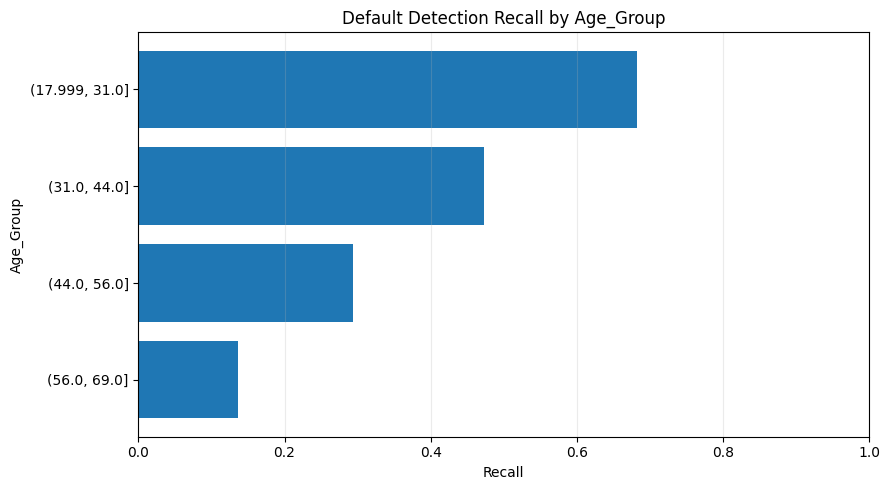

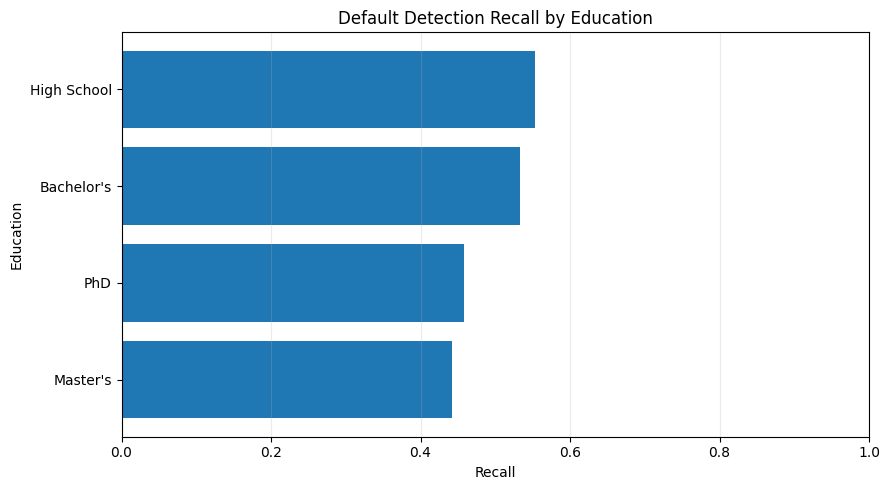

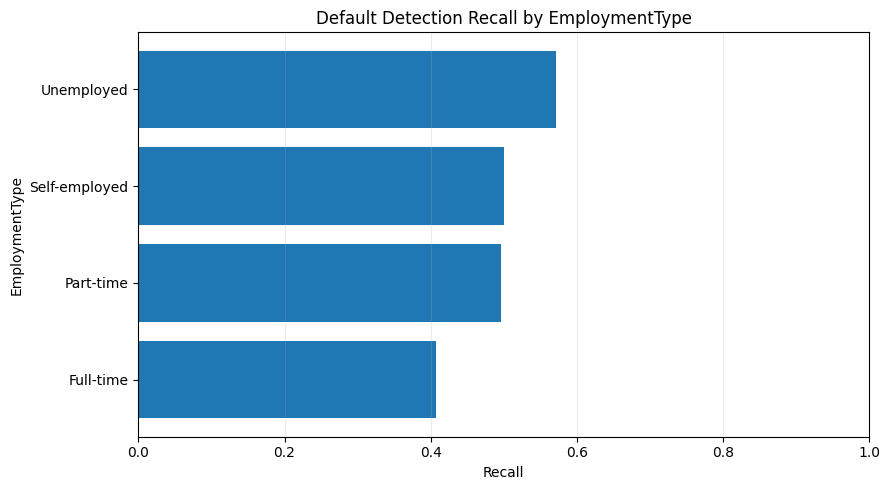

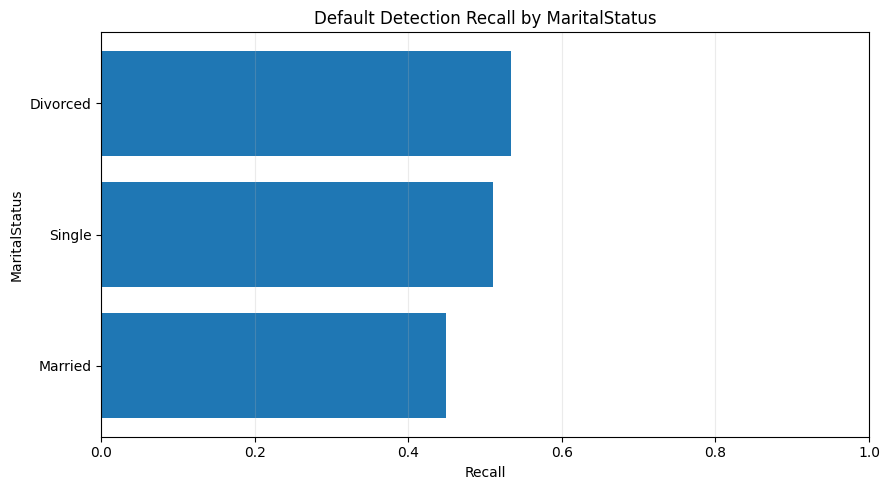

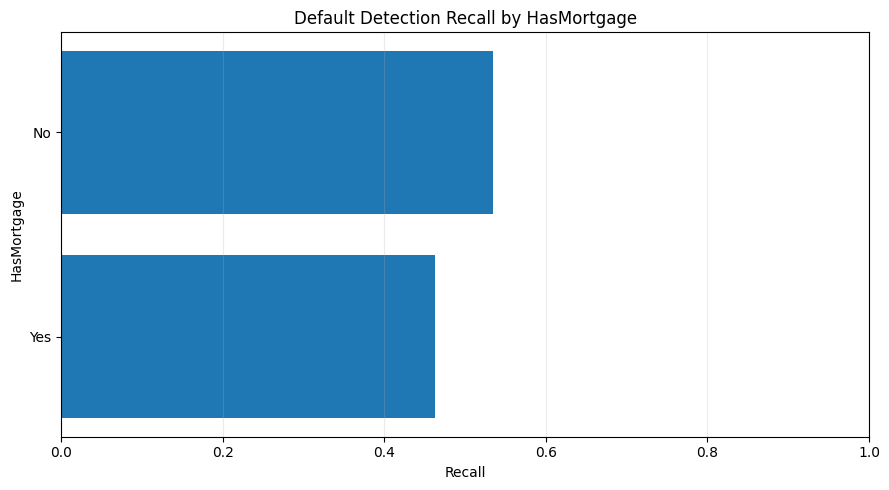

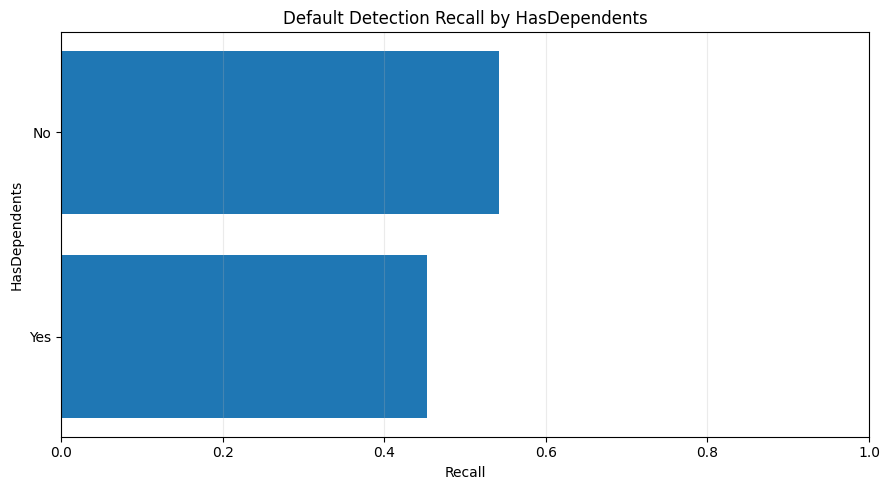

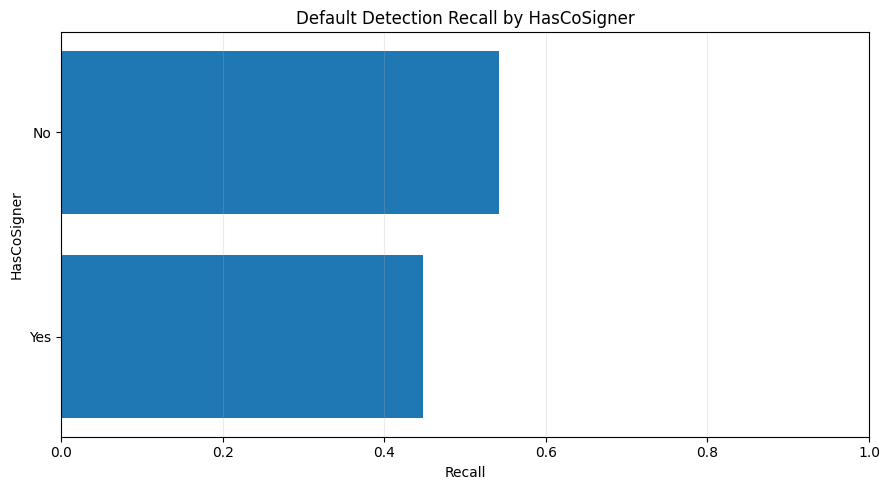

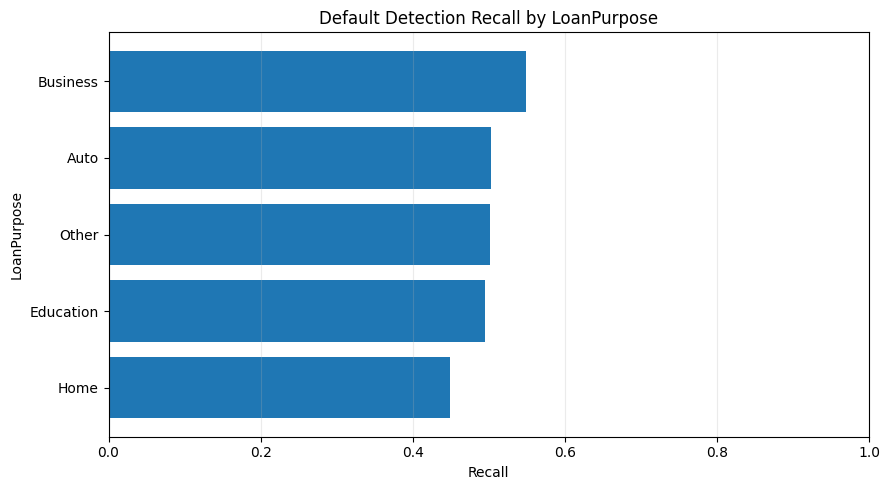

In [79]:
for feature in group_columns:

    plot_data = subgroup_comparison[
        subgroup_comparison["Feature"] == feature
    ].sort_values("Recall")

    plt.figure(figsize=(9, 5))

    plt.barh(
        plot_data["Group"],
        plot_data["Recall"]
    )

    plt.xlabel("Recall")
    plt.ylabel(feature)
    plt.title(f"Default Detection Recall by {feature}")
    plt.xlim(0, 1)
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

**SMOTE and hyperparameter tuning with cross-validation**

In [80]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.base import clone
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=30000,
    random_state=42,
    stratify=y_train
)

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

tuning_models = {
    "XGBoost": (
        XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        ),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [3, 5, 7],
            "classifier__learning_rate": [0.03, 0.05, 0.1],
            "classifier__subsample": [0.8, 1.0]
        }
    ),
    "LightGBM": (
        LGBMClassifier(
            random_state=42,
            verbosity=-1,
            n_jobs=1
        ),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [3, 5, 7],
            "classifier__learning_rate": [0.03, 0.05, 0.1],
            "classifier__subsample": [0.8, 1.0]
        }
    )
}

tuned_searches = {}
tuning_results = []

for name, (model, parameters) in tuning_models.items():

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("smote", SMOTE(random_state=42)),
        ("classifier", model)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters,
        n_iter=4,
        scoring="average_precision",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    search.fit(X_tune, y_tune)

    tuned_searches[name] = search

    tuning_results.append({
        "Model": name,
        "Best CV PR-AUC": search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_comparison = pd.DataFrame(tuning_results)

display(tuning_comparison.round(4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Fitting 3 folds for each of 4 candidates, totalling 12 fits


,Model,Best CV PR-AUC,Best Parameters
0,XGBoost,0.3057,"{'classifier__subsample': 0.8, 'classifier__n_..."
1,LightGBM,0.3040,"{'classifier__subsample': 0.8, 'classifier__n_..."


Evaluate tuned models on validation data

In [81]:
X_subtrain_original, X_val_original, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [82]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

smote_validation_results = []
smote_validation_predictions = {}

for name, search in tuned_searches.items():

    model = search.best_estimator_

    probabilities = model.predict_proba(X_val_original)[:, 1]

    thresholds = np.arange(0.05, 0.96, 0.01)

    best_result = None

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        current_f1 = f1_score(
            y_val,
            predictions,
            zero_division=0
        )

        if best_result is None or current_f1 > best_result["F1-Score"]:

            best_result = {
                "Threshold": threshold,
                "Accuracy": accuracy_score(y_val, predictions),
                "Precision": precision_score(y_val, predictions, zero_division=0),
                "Recall": recall_score(y_val, predictions, zero_division=0),
                "F1-Score": current_f1,
                "PR-AUC": average_precision_score(y_val, probabilities)
            }

    smote_validation_results.append({
        "Model": name,
        **best_result
    })

    smote_validation_predictions[name] = probabilities

smote_validation_comparison = pd.DataFrame(
    smote_validation_results
)

display(
    smote_validation_comparison
    .sort_values("F1-Score", ascending=False)
    .round(4)
)

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,PR-AUC
0,XGBoost,0.23,0.7884,0.2716,0.4888,0.3492,0.3023
1,LightGBM,0.23,0.7881,0.2708,0.4876,0.3482,0.3025


In [83]:
final_approach_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Approach": "Class-Weighted + Calibration",
        "Validation F1": 0.3676,
        "Validation PR-AUC": 0.3362
    },
    {
        "Model": "XGBoost",
        "Approach": "Class-Weighted",
        "Validation F1": 0.3580,
        "Validation PR-AUC": 0.3302
    },
    {
        "Model": "LightGBM",
        "Approach": "Class-Weighted",
        "Validation F1": 0.3636,
        "Validation PR-AUC": 0.3318
    }
])

smote_comparison_rows = smote_validation_comparison.copy()

smote_comparison_rows["Approach"] = "SMOTE + Hyperparameter Tuning"

smote_comparison_rows = smote_comparison_rows.rename(columns={
    "F1-Score": "Validation F1",
    "PR-AUC": "Validation PR-AUC"
})

final_approach_comparison = pd.concat([
    final_approach_comparison,
    smote_comparison_rows[
        ["Model", "Approach", "Validation F1", "Validation PR-AUC"]
    ]
], ignore_index=True)

display(
    final_approach_comparison
    .sort_values("Validation F1", ascending=False)
    .round(4)
)

,Model,Approach,Validation F1,Validation PR-AUC
0,Logistic Regression,Class-Weighted + Calibration,0.3676,0.3362
2,LightGBM,Class-Weighted,0.3636,0.3318
1,XGBoost,Class-Weighted,0.3580,0.3302
3,XGBoost,SMOTE + Hyperparameter Tuning,0.3492,0.3023
4,LightGBM,SMOTE + Hyperparameter Tuning,0.3482,0.3025
